[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/QMLP_AdversarialRobustness_Nowmi2025.ipynb)

# QMLP adversarial robustness: "SoK: Critical Evaluation of Quantum Machine Learning for Adversarial Robustness" step by step

**Paper.** Saeefa Rubaiyet Nowmi, Jesus Lopez, Md Mahmudul Alam Imon, Shahrooz Pouryousef and Mohammad Saidur Rahman,
*SoK: Critical Evaluation of Quantum Machine Learning for Adversarial Robustness*, accepted at IEEE Symposium on Security and Privacy (S&P) 2026;
arXiv:2511.14989 (2025), https://arxiv.org/abs/2511.14989.  Authors' code and data: https://github.com/IQSeC-Lab/SoK-QML (project page https://iqsec-lab.github.io/SoK-QML/).

**What this notebook does.** The paper is a "systematisation of knowledge" (a survey with a taxonomy of attacks on quantum machine learning), **but Sections 4-5 contain
their own experiments**, and this notebook re-runs the ones that fit on a CPU:

1. the 9-qubit **QMLP** (quantum multilayer perceptron: encoding, Rot + CRX layers, Pauli-Z read-out, linear head) with *angle* and *amplitude* encoding and a classical **CMLP**, on
   **MNIST** (10 classes) and **AZ-Class** (23 Android-malware families) - Table 2;
2. **50 % label flipping** with and without label smoothing - Table 3;
3. the quantum-specific **QUID** poisoning attack with and without the **Q-Detection** defence - Tables 4 and 5;
4. the clean-label **Huang-Zhang (HZ) backdoor** - Table 6, and the circuit-level **QTrojan** backdoor - Table 7;
5. white-box **FGSM** and **PGD** evasion - Table 8.

Every number is printed next to the paper's number with a verdict (reproduced / not reached / exceeded / cannot be checked).  The depolarizing-noise columns, the 50-layer models and the
hardware-level parts cannot be run here and are marked as such.  The notebook also contains three audit findings about the experimental protocol (how the CMLP label-flipping number is obtained, clamping of PCA features, model selection on the test set), see Sections 6, 10 and 12.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*.  `FAST_MODE = True` (default) is a class-sized demo with small budgets; set `FAST_MODE = False` in the configuration cell for the larger budgets
(documented there, several hours on a CPU).  No account, token or GPU is needed: MNIST and AZ-Class are public files in the authors' GitHub repository.

**Runtime of the committed outputs.** The outputs stored in this notebook come from one `FAST_MODE = True` execution on a CPU shared with many other jobs (8 logical cores, PyTorch 2 threads): 158 minutes wall-clock (an earlier, less loaded execution of the same cells took 50 minutes; on an idle machine it should be much shorter, not measured). The `FAST_MODE = False` budgets were not run to completion (they need several hours); that code path was only smoke-tested with tiny budgets.

**What you get at the end.** Real-data exploration plots, the circuits that were actually executed, Tables 2-8 rebuilt side by side with the paper, a per-claim verdict table, a critical reading and exercises.


## The paper in one page

* **Problem.** How robust are quantum machine-learning (QML) classifiers against *classical-style* and *quantum-specific* attacks, and is the encoding / circuit depth a security-relevant design choice?
* **Taxonomy (Sections 3, 6).** Attacks are grouped by adversary access (black-, gray-, white-box) and phase (training, inference, dual-phase).  Most of that part is a literature survey (it cannot be "reproduced").
* **Model (Section 4).** `QMLP`: 9 qubits simulated with PennyLane `default.qubit` + PyTorch.  *Angle encoding*: 9 PCA components, `AngleEmbedding` (RX) **re-uploaded in every layer**;
  *amplitude encoding*: 512 PCA components loaded once with `AmplitudeEmbedding`.  Each layer = `Rot` on every qubit + a ring of `CRX` gates (qubit i controls qubit i+1 mod 9); read-out = the 9 Pauli-Z expectations, followed by a `Linear(9 -> classes)` layer.
  Depths 2, 5, 10, 50.  Adam, lr 0.001, weight decay, batch 64, 30 epochs, early stopping (patience 5) for attacks, 3 seeds.  Noise: depolarizing p = 0.01 on the transpiled gates (Qiskit Aer / `default.mixed`).
  The classical **CMLP** is a "similar" MLP on the *unreduced* features.
* **Data.** MNIST and AZ-Class (MADAR family, 23 classes); full data for baseline / label flipping / FGSM / PGD, a class-balanced subset (700 per class, 7,000 / 16,100 training samples, 2,000 test samples) for QUID, backdoors and QTrojan.
* **Headline claims.** (i) Noiseless: deep amplitude-encoded QMLPs beat angle-encoded ones (92.6 % vs 66-84 % on MNIST); under noise shallow angle circuits are the only ones that keep working.  (ii) QMLPs keep ~90 % of their accuracy under 50 % label flipping while the CMLP keeps ~50 %.
  (iii) QUID is very effective (ASR > 85 % at 50 % poisoning).  (iv) The HZ backdoor reaches ASR ~100 % on amplitude encoding; QTrojan *fails* (ASR at chance) with 10 or 23 classes.
  (v) QMLPs are much *more* vulnerable to FGSM/PGD than the CMLP (relative accuracy 0.05 vs 0.33 at eps = 0.10 on MNIST).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Model, loss, optimiser | 9-qubit QMLP, Adam, batch 64, lr 0.001, weight decay | same architecture (exact PyTorch state-vector simulator, asserted equal to the PennyLane QNode in the circuit section below); weight decay 1e-4 and the TorchLayer init U(0, 2 pi) are taken from the authors' code (`# CHOICE`) |
| Angle-encoding input | "PCA to nine components" | the authors' code first shrinks every MNIST image to **3 x 3 pixels**, then MinMax -> PCA(9); we do the same (`# CHOICE`, explains the low accuracy). The PCA coordinates are used **directly as radians** (no scaling to [0, pi]) |
| Amplitude input | PCA to 512 components, normalised | 784 pixels -> MinMax -> PCA(512) -> `AmplitudeEmbedding(normalize=True)` |
| AZ-Class | MADAR AZ-Class, 23 classes, full dataset | the authors' `.npz` files (184,342 x 2,439 train, 20,482 test); only a **random pool** is kept in memory (`AZ_POOL_ROWS` train rows, `AZ_TEST_ROWS` test rows) and PCA/MinMax are fitted on at most `PCA_FIT_ROWS` of them (`# CHOICE`, memory) |
| Training / epochs | 30 epochs, early stopping on the **test** set (authors' code) | fixed epoch budget; the epoch with the best accuracy on a **clean validation split** is kept (no test-set selection, `# CHOICE`); `FAST_MODE` uses a larger lr (0.05) and 8 epochs |
| Subset protocol | 700 / class train, 2,000 test | `SUB_PER_CLASS` / class (FAST: 120), `TEST_N` test samples; a class-balanced validation split is added |
| "Full data" runs | whole dataset, all QMLP depths | CMLP on the whole training pool; QMLP "F" runs only in the full configuration, capped at `FULL_TRAIN_CAP` rows (`# CHOICE`, simulator cost) |
| Noise (p = 0.01) | density-matrix / Aer simulations | **not run** (cannot be checked); all numbers here are noiseless |
| Label flipping | 50 % untargeted, label smoothing 0.2 | exactly that: a random 50 % of the labels is replaced by a uniformly random *wrong* label; smoothing 0.2 |
| QUID | prototype density matrices precomputed from the training data, Frobenius distance, flip to the farthest class | same; prototypes are the mean density matrix of each class of the (sub)set, computed in closed form from overlaps (no 512 x 512 matrices) |
| Q-Detection | Q-WAN as a bi-level QUBO, simulated annealing, eta 0.05, alpha 1.0, beta in [0.1, 2], 50 sweeps | a faithful NumPy port of the authors' `QWANIsingBank` (30 beta steps x 50 sweeps, free and guided phase); fewer mini-batch steps in `FAST_MODE` |
| HZ backdoor | trigger via fuzzy admix + Q-FGSM, L_inf eps | the authors' Algorithm 1 (eps 0.2, fuzzy admix (c, sigma) = (1, 2), n = 3, stop at fooling rate 0.6); the trigger search uses `HZ_TRIGGER_SAMPLES` non-target samples and `HZ_IMAX` outer iterations; target class 7 |
| QTrojan | RX(pi/2) before and RX(3pi/2) + RY(theta) after the encoding, target 0, theta = pi/4 | exactly that, on the clean trained angle models |
| FGSM / PGD | eps in {0.01, 0.10, 0.15}; relative accuracy | the authors' evaluation code: FGSM one step, PGD 10 steps (step 1.25 eps / 10, random start), **inputs clamped to [0, 1] after the attack**; the CMLP is attacked with the authors' classical PGD script (40 steps of 0.01, no random start); we additionally report an unclamped variant for the QMLPs (see Section 10) |

### Where the extracted paper text is ambiguous (stated, not guessed)

* **Table 2 headers** are garbled in the PDF text ("AZ-Class MNIST / NL DN NL DN / F. S. F. S. F. S. F. S."). We read every row as AZ-Class (noiseless-F, noiseless-S, depolarized-F, depolarized-S) followed by the same four columns for MNIST;
  this matches the prose (angle, 2 layers: 66.0 % MNIST and 49.8 % AZ-Class; amplitude, 50 layers: 92.6 % and 67.0 %). The CMLP row has the single "F" values 95.89 % (AZ-Class) and 96.63 % (MNIST).
* **Table 3** has the same layout (AZ-Class AccNL, AccDN, then MNIST AccNL, AccDN); we use the noiseless columns. The prose says label smoothing lifts the CMLP "from 0.51 to 0.59 on MNIST", but the table gives 0.51 -> 0.59 for AZ-Class and 0.50 -> 0.51 for MNIST; we follow the table.
* **Table 8** shows only 2 and 50 layers; the 5- and 10-layer results are only in the authors' repository.
* **Which model is attacked in Table 8, 5.4-5.5** (trained on the full or the subset data) is not stated for every table; we always attack our own subset-trained models.


## 1. Setup

The next cell installs the pinned library (PennyLane 0.45.1 was the tested version; Colab already ships PyTorch, NumPy, pandas, scikit-learn and matplotlib - if pip upgrades NumPy, restart the runtime once).
The configuration cell holds every tunable constant, including the two budgets (`FAST_MODE`).

In [1]:
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules


def _missing():
    for mod in ("pennylane", "torch", "sklearn", "PIL", "requests", "pandas", "matplotlib"):
        try:
            importlib.import_module(mod)
        except Exception:
            return True
    return False


if IN_COLAB or _missing():       # guarded: does not reinstall in a prepared local environment
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "pillow", "requests"], check=True)
    # Colab already ships torch, numpy, pandas, scikit-learn, matplotlib.  If pip upgraded numpy, restart the runtime once and run again.
print("tested with: pennylane 0.45.1, torch 2.14 (CPU), numpy 2.x, scikit-learn 1.x, Python 3.12")


tested with: pennylane 0.45.1, torch 2.14 (CPU), numpy 2.x, scikit-learn 1.x, Python 3.12


### Configuration

All budgets live here.  **Full-run budgets (`FAST_MODE = False`)**: 3 seeds, 700 samples per class, 30 epochs (lr 0.001), layers angle {2, 5, 10} and amplitude {2, 10}, QMLP "full data" runs on 20,000 rows,
both datasets for every attack, Q-Detection and the HZ backdoor at all three poison ratios, an unclamped control for the HZ backdoor. Expect several hours on a free Colab CPU; the 50-layer models of the paper are not run in either mode.

In [2]:
# ===================== configuration: every tunable constant lives here =====================
import math, os

SEED = 42
FAST_MODE = True            # True: small class demo (see budgets below).  False: the larger "full" budgets.
IBM_TOKEN = ""              # not used (the paper simulates everything); kept for the factory convention
DATA_DIR = "qc222_data"     # downloads are cached here
os.makedirs(DATA_DIR, exist_ok=True)

# --- model (same in every experiment, as in the paper) ---
N_QUBITS = 9                # 2**9 = 512 amplitudes
BATCH_SIZE = 64             # paper: batch size 64
WEIGHT_DECAY = 1e-4         # paper: "weight decay" (value taken from the authors' released code)
LAYERS_ANGLE = [2]          # paper: 2, 5, 10 (and 50 only for FGSM/PGD)
LAYERS_AMP = [2]            # paper: 2, 10, 50

# --- attacks (values from the paper / the authors' code) ---
LF_RATIO = 0.5              # Table 3: 50 % untargeted label flipping
SMOOTHING = 0.2             # label smoothing alpha = 0.2
EPS_LIST = [0.01, 0.10, 0.15]   # Table 8: FGSM / PGD perturbation sizes
PGD_STEPS = 10              # authors' evaluation code: 10 PGD steps, step = 1.25 * eps / 10, random start
QUID_RATIOS = [0.1, 0.3, 0.5]   # Tables 4-5: poison ratios
QD_ETA, QD_ALPHA, QD_BETA = 0.05, 1.0, (0.1, 2.0)   # Q-Detection: eta=0.05, alpha=1.0, beta in [0.1, 2.0]
QD_SWEEPS = 50              # 50 annealing sweeps
TROJAN_TARGET, TROJAN_THETA = 0, math.pi / 4        # QTrojan: target class 0, theta_target = pi/4
HZ_TARGET, HZ_EPS = 7, 0.2  # Huang-Zhang backdoor: target class, trigger L_inf radius (authors' code defaults)
HZ_FUZZY_C, HZ_FUZZY_SIGMA, HZ_ADMIX_N = 1.0, 2.0, 3
HZ_FOOL_THRESHOLD = 0.6

# --- compute budgets ---
if FAST_MODE:               # target: about 10 minutes on an idle CPU (see the runtime note in the introduction)
    N_SEEDS = 1             # paper: 3 seeds
    SUB_PER_CLASS = 100     # paper: 700 per class
    VAL_PER_CLASS = 40      # clean validation split (model selection; the authors selected on the test set)
    TEST_N = 1000           # paper: 2000 test samples for the subset experiments
    EPOCHS_Q, LR_Q = 8, 0.05        # paper: 30 epochs, lr 0.001 (too slow for a class demo -> larger lr, fewer epochs)
    EPOCHS_C, LR_C = 6, 0.001       # classical MLP
    FULL_TRAIN_CAP = None   # the "F" (full-data) QMLP runs of Table 2 are skipped in FAST mode
    CMLP_FULL_EPOCHS = 3
    AZ_POOL_ROWS, AZ_TEST_ROWS = 24000, 2000   # AZ-Class rows kept in memory (full set: 184,342 train / 20,482 test)
    ATTACK_DATASETS = ["MNIST"]
    ATTACK_N = 300          # test samples attacked with FGSM / PGD
    QD_RATIOS = [0.3]       # poison ratios for which Q-Detection is run
    QD_STEPS_PER_BATCH = 1
    HZ_RATIOS = [0.3]
    HZ_TRIGGER_SAMPLES, HZ_IMAX = 60, 3
    HZ_CONTROL = True
    PCA_FIT_ROWS = 20000
else:                       # the larger budget: roughly 2-3 h on a Colab CPU runtime
    N_SEEDS = 3
    SUB_PER_CLASS = 700
    VAL_PER_CLASS = 100
    TEST_N = 2000
    EPOCHS_Q, LR_Q = 30, 0.001
    EPOCHS_C, LR_C = 30, 0.001
    FULL_TRAIN_CAP = 20000
    CMLP_FULL_EPOCHS = 30
    AZ_POOL_ROWS, AZ_TEST_ROWS = 50000, 4000
    ATTACK_DATASETS = ["MNIST", "AZ"]
    ATTACK_N = 1000
    QD_RATIOS = [0.1, 0.3, 0.5]
    QD_STEPS_PER_BATCH = 2
    HZ_RATIOS = [0.1, 0.3, 0.5]
    HZ_TRIGGER_SAMPLES, HZ_IMAX = 500, 20
    HZ_CONTROL = True
    PCA_FIT_ROWS = 60000
    LAYERS_ANGLE = [2, 5, 10]
    LAYERS_AMP = [2, 10]

DATASETS = ["MNIST", "AZ"]
N_THREADS = max(1, (os.cpu_count() or 2) // 2)
print(f"FAST_MODE={FAST_MODE}  seeds={N_SEEDS}  train/class={SUB_PER_CLASS}  test={TEST_N}  "
      f"epochs(Q)={EPOCHS_Q}  layers angle={LAYERS_ANGLE} amplitude={LAYERS_AMP}")


FAST_MODE=True  seeds=1  train/class=100  test=1000  epochs(Q)=8  layers angle=[2] amplitude=[2]


In [3]:
# ===================== imports, seeds, versions =====================
import os, sys, io, gzip, math, time, zipfile, random, warnings, struct, json
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

torch.set_num_threads(N_THREADS)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
rng_global = np.random.default_rng(SEED)
HF_TOKEN = os.environ.get("HF_TOKEN")      # not needed here: every dataset of this paper is public (GitHub)
print("torch", torch.__version__, "| pennylane", qml.__version__, "| numpy", np.__version__,
      "| sklearn", sklearn.__version__, "| threads", torch.get_num_threads())


torch 2.14.1+cpu | pennylane 0.45.1 | numpy 2.5.4 | sklearn 1.9.1 | threads 4


## 2. The data

Both datasets are public files in the authors' repository (`Datasets/MNIST`, `Datasets/AZ_23`); MNIST has two further mirrors as fallback. Large arrays are read in chunks and only a random pool of AZ-Class rows is kept in memory.
The AZ-Class files are numeric arrays of 2,439 behavioural features (all scaled to [0, 1]) with integer family labels 0-22 (the family names are not part of the files).
Preprocessing, fitted **on the training pool only**:

* CMLP input: raw pixels in [0, 1] (MNIST) or the raw 2,439 features (AZ-Class);
* angle input: (MNIST: shrink to 3 x 3) -> MinMaxScaler -> PCA(9);
* amplitude input: MinMaxScaler -> PCA(512) (then L2-normalised inside `AmplitudeEmbedding`).

In [4]:
GH_RAW = "https://raw.githubusercontent.com/IQSeC-Lab/SoK-QML/main/Datasets/"      # the paper's own repository
MNIST_MIRRORS = [GH_RAW + "MNIST/{name}",
                 "https://ossci-datasets.s3.amazonaws.com/mnist/{name}",
                 "https://storage.googleapis.com/cvdf-datasets/mnist/{name}"]


def download(urls, dest, min_bytes=1000):
    """Download the first working URL to dest (cached)."""
    if os.path.exists(dest) and os.path.getsize(dest) > min_bytes:
        return dest
    last = None
    for u in urls:
        try:
            r = requests.get(u, timeout=120)
            if r.status_code == 200 and len(r.content) > min_bytes:
                with open(dest, "wb") as f:
                    f.write(r.content)
                return dest
            last = f"{u} -> HTTP {r.status_code}"
        except Exception as e:                                   # network problems: try the next mirror
            last = f"{u} -> {type(e).__name__}"
    raise RuntimeError(f"could not download {os.path.basename(dest)} ({last})")


def read_idx(path):
    with gzip.open(path, "rb") as f:
        data = f.read()
    magic, = struct.unpack(">I", data[:4])
    nd = magic & 0xFF
    dims = struct.unpack(">" + "I" * nd, data[4:4 + 4 * nd])
    return np.frombuffer(data, dtype=np.uint8, offset=4 + 4 * nd).reshape(dims)


def load_mnist_raw():
    files = {"xtr": "train-images-idx3-ubyte.gz", "ytr": "train-labels-idx1-ubyte.gz",
             "xte": "t10k-images-idx3-ubyte.gz", "yte": "t10k-labels-idx1-ubyte.gz"}
    out = {}
    for k, name in files.items():
        p = download([m.format(name=name) for m in MNIST_MIRRORS], os.path.join(DATA_DIR, name))
        out[k] = read_idx(p)
    return out["xtr"], out["ytr"].astype(np.int64), out["xte"], out["yte"].astype(np.int64)


def downscale_3x3(images_u8):
    """The authors' angle-encoding pipeline first shrinks every 28x28 image to 3x3 (= 9 numbers) with PIL bilinear resize."""
    out = np.empty((len(images_u8), 9), dtype=np.float32)
    for i, im in enumerate(images_u8):
        out[i] = np.asarray(Image.fromarray(im).resize((3, 3), Image.BILINEAR), dtype=np.float32).reshape(-1) / 255.0
    return out


def npz_member_rows(path, key, rows=None, chunk_rows=4000):
    """Read selected rows of a (n, d) .npy member of an .npz without decompressing the whole array into memory."""
    with zipfile.ZipFile(path) as z:
        name = key + ".npy"
        with z.open(name) as f:
            ver = np.lib.format.read_magic(f)
            shape, fortran, dtype = (np.lib.format.read_array_header_1_0(f) if ver == (1, 0)
                                     else np.lib.format.read_array_header_2_0(f))
            n = shape[0]
            if len(shape) == 1:
                return np.frombuffer(f.read(), dtype=dtype)[:n].copy() if rows is None else np.frombuffer(f.read(), dtype=dtype)[rows].copy()
            d = shape[1]
            rows = np.arange(n) if rows is None else np.asarray(rows)
            out = np.empty((len(rows), d), dtype=dtype)
            pos = 0
            for start in range(0, n, chunk_rows):
                m = min(chunk_rows, n - start)
                buf = np.frombuffer(f.read(m * d * dtype.itemsize), dtype=dtype).reshape(m, d)
                lo, hi = np.searchsorted(rows, start), np.searchsorted(rows, start + m)
                if hi > lo:
                    out[lo:hi] = buf[rows[lo:hi] - start]
            return out


def load_az_rows(pool_rows, test_rows, seed):
    """AZ-Class (23 Android-malware families, 2,439 behavioural features) from the paper's GitHub repo."""
    ptr = download([GH_RAW + "AZ_23/AZ-Class-Task_23_families_train.npz"], os.path.join(DATA_DIR, "az_train.npz"), 10**6)
    pte = download([GH_RAW + "AZ_23/AZ-Class-Task_23_families_test.npz"], os.path.join(DATA_DIR, "az_test.npz"), 10**5)
    rng = np.random.default_rng(seed)
    ytr_all = npz_member_rows(ptr, "Y_train")
    yte_all = npz_member_rows(pte, "Y_test")
    itr = np.sort(rng.choice(len(ytr_all), size=min(pool_rows, len(ytr_all)), replace=False))
    ite = np.sort(rng.choice(len(yte_all), size=min(test_rows, len(yte_all)), replace=False))
    Xtr = npz_member_rows(ptr, "X_train", itr)
    Xte = npz_member_rows(pte, "X_test", ite)
    return Xtr, ytr_all[itr].astype(np.int64), Xte, yte_all[ite].astype(np.int64), len(ytr_all), len(yte_all)


def fit_features(Xtr_raw, Xte_raw, n_components, fit_rows, seed):
    """MinMaxScaler -> PCA(n_components), both fitted on (a subsample of) the TRAINING pool only, then applied to train and test."""
    rng = np.random.default_rng(seed)
    sel = rng.choice(len(Xtr_raw), size=min(fit_rows, len(Xtr_raw)), replace=False)
    sc = MinMaxScaler().fit(Xtr_raw[sel])
    pca = PCA(n_components=n_components, svd_solver="randomized" if n_components > 20 else "full", random_state=seed)
    pca.fit(sc.transform(Xtr_raw[sel]))
    f = lambda X: pca.transform(sc.transform(X)).astype(np.float32)
    return f(Xtr_raw), f(Xte_raw), pca


DATA = {}
t0 = time.time()
xtr, ytr_m, xte, yte_m = load_mnist_raw()
D = dict(name="MNIST", n_classes=10, y_tr=ytr_m, y_te=yte_m)
D["Xc_tr"] = (xtr.reshape(len(xtr), -1) / 255.0).astype(np.float32)           # classical MLP input: 784 pixels in [0,1]
D["Xc_te"] = (xte.reshape(len(xte), -1) / 255.0).astype(np.float32)
D["A_tr"], D["A_te"], D["pca_angle"] = fit_features(downscale_3x3(xtr), downscale_3x3(xte), N_QUBITS, PCA_FIT_ROWS, SEED)   # 3x3 -> MinMax -> PCA(9)
D["M_tr"], D["M_te"], D["pca_amp"] = fit_features(D["Xc_tr"], D["Xc_te"], 512, PCA_FIT_ROWS, SEED)                       # 784 -> MinMax -> PCA(512)
D["raw_images_tr"], D["raw_images_te"] = xtr, xte
D["class_names"] = [str(c) for c in range(10)]
DATA["MNIST"] = D
print(f"MNIST ready in {time.time() - t0:.0f}s: train {D['Xc_tr'].shape}, test {D['Xc_te'].shape}")

AZ_OK = True
try:
    t0 = time.time()
    a_xtr, a_ytr, a_xte, a_yte, n_tr_all, n_te_all = load_az_rows(AZ_POOL_ROWS, AZ_TEST_ROWS, SEED)
    D = dict(name="AZ", n_classes=23, y_tr=a_ytr, y_te=a_yte, full_sizes=(n_tr_all, n_te_all))
    D["Xc_tr"], D["Xc_te"] = a_xtr, a_xte
    D["A_tr"], D["A_te"], D["pca_angle"] = fit_features(a_xtr, a_xte, N_QUBITS, PCA_FIT_ROWS, SEED)
    D["M_tr"], D["M_te"], D["pca_amp"] = fit_features(a_xtr, a_xte, 512, PCA_FIT_ROWS, SEED)
    D["class_names"] = [f"family {c}" for c in range(23)]     # the .npz files contain integer labels only (no family names)
    DATA["AZ"] = D
    print(f"AZ-Class ready in {time.time() - t0:.0f}s: pool {a_xtr.shape} of {n_tr_all} train rows, test {a_xte.shape} of {n_te_all}")
except Exception as e:
    AZ_OK = False
    print("AZ-Class is NOT available in this session -> BLOCKED for AZ, MNIST only.  Reason:", repr(e))
DATASETS = [d for d in DATASETS if d in DATA]


MNIST ready in 52s: train (60000, 784), test (10000, 784)


AZ-Class ready in 385s: pool (24000, 2439) of 184342 train rows, test (2000, 2439) of 20482


## Dataset Exploration and Visualisation

For both datasets: shapes, feature names, original label values and class counts, the real class distribution, and 2-D scatter plots in which **every point is a real observation coloured by its ground-truth class**
(PCA fitted on the training pool).  The first scatter is exactly what the angle encoding sees: the raw PCA coordinates are used as rotation angles in radians (the authors do not rescale them to [0, pi]);
the second is the leading plane of the 512-D amplitude input. The printed fraction of coordinates outside [0, 1] matters later (Section 10).

MNIST: train pool (60000, 784), test (10000, 784), classes 10
  raw features: 784 pixels (pixel_r_c, r,c = 0..27), values in [0,1];  angle-encoding input: 3x3 downscale -> MinMax -> PCA(9): PC1..PC9;  amplitude-encoding input: MinMax -> PCA(512): PC1..PC512
  original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


 label name  train pool  test
     0    0        5923   980
     1    1        6742  1135
     2    2        5958  1032
     3    3        6131  1010
     4    4        5842   982
     5    5        5421   892
     6    6        5918   958
     7    7        6265  1028
     8    8        5851   974
     9    9        5949  1009


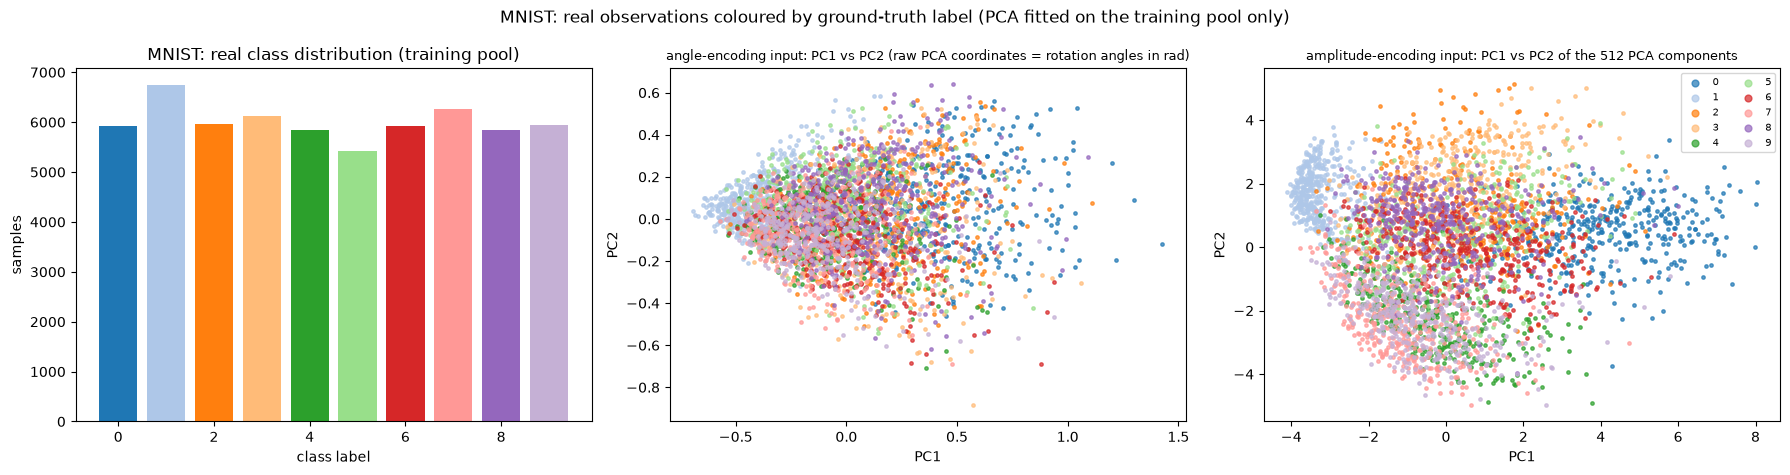

  MNIST: angle features lie in [-0.94, 1.81]; 51.2% of the 9-D coordinates are OUTSIDE [0, 1] (relevant for the FGSM/PGD clamp, see Section 10).  Amplitude features: 51.0% outside [0, 1].
AZ: train pool (24000, 2439), test (2000, 2439), classes 23
  raw features: 2,439 behavioural features feature_0..feature_2438 (values in [0,1]; names are not given in the .npz); full dataset has 184342 train / 20482 test rows, we keep a random pool of 24000 / 2000
  angle-encoding input: MinMax -> PCA(9): PC1..PC9;  amplitude-encoding input: MinMax -> PCA(512): PC1..PC512
  original label values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
 label      name  train pool  test
     0  family 0        1218    85
     1  family 1        1125    96
     2  family 2        1190   116
     3  family 3        1188   109
     4  family 4         784    77
     5  family 5        1175    88
     6  family 6        1224    97
     7  family 7        1143    81
     8  famil

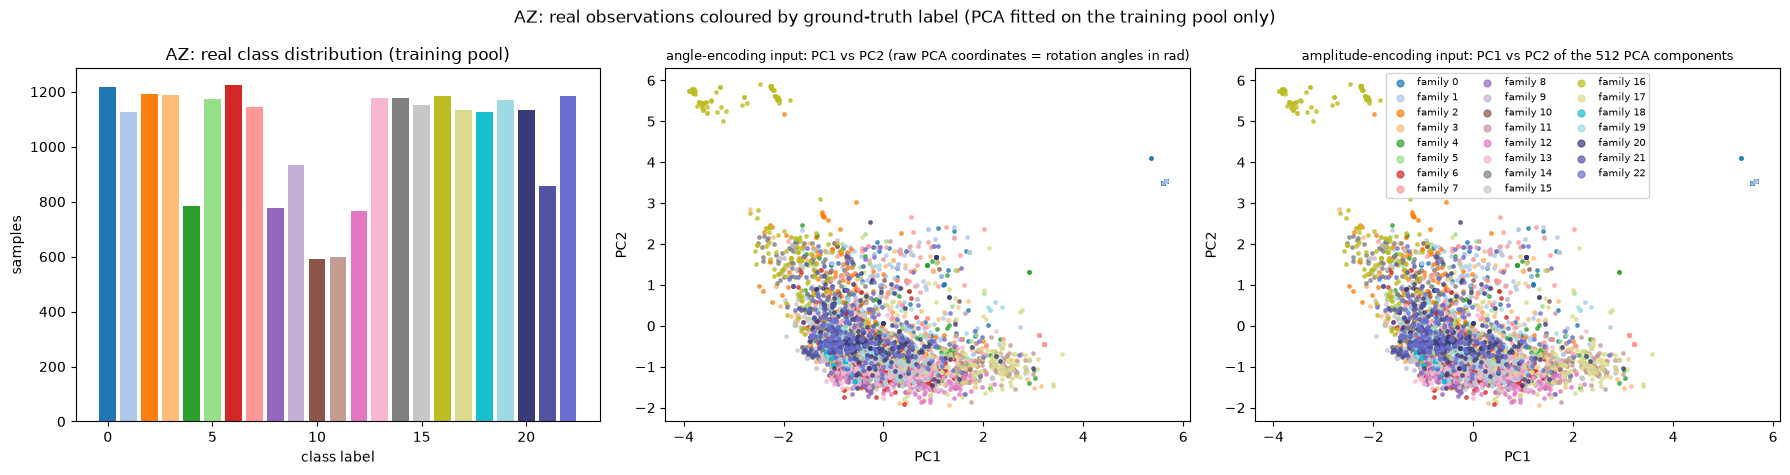

  AZ: angle features lie in [-3.89, 6.04]; 67.5% of the 9-D coordinates are OUTSIDE [0, 1] (relevant for the FGSM/PGD clamp, see Section 10).  Amplitude features: 50.9% outside [0, 1].


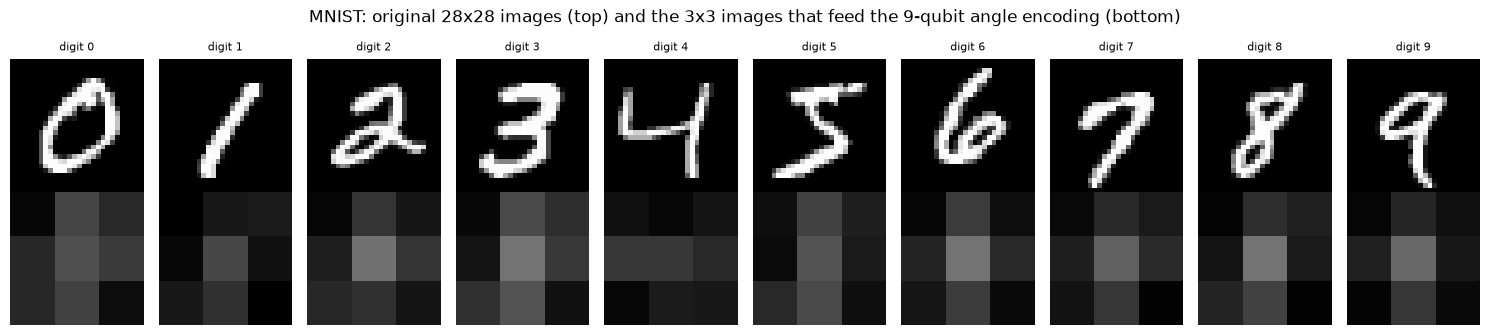

In [5]:
PALETTE = list(plt.cm.tab20(np.arange(20))) + list(plt.cm.tab20b(np.arange(8)))


def class_table(D):
    tr = pd.Series(D["y_tr"]).value_counts().sort_index()
    te = pd.Series(D["y_te"]).value_counts().sort_index()
    return pd.DataFrame({"label": tr.index, "name": [D["class_names"][i] for i in tr.index], "train pool": tr.values,
                         "test": te.reindex(tr.index).fillna(0).astype(int).values})


for name in DATASETS:
    D = DATA[name]
    print("=" * 100)
    print(f"{name}: train pool {D['Xc_tr'].shape}, test {D['Xc_te'].shape}, classes {D['n_classes']}")
    if name == "MNIST":
        print("  raw features: 784 pixels (pixel_r_c, r,c = 0..27), values in [0,1];  angle-encoding input: 3x3 downscale -> MinMax -> PCA(9): PC1..PC9;"
              "  amplitude-encoding input: MinMax -> PCA(512): PC1..PC512")
    else:
        print(f"  raw features: 2,439 behavioural features feature_0..feature_2438 (values in [0,1]; names are not given in the .npz); "
              f"full dataset has {D['full_sizes'][0]} train / {D['full_sizes'][1]} test rows, we keep a random pool of {len(D['y_tr'])} / {len(D['y_te'])}")
        print("  angle-encoding input: MinMax -> PCA(9): PC1..PC9;  amplitude-encoding input: MinMax -> PCA(512): PC1..PC512")
    print("  original label values:", sorted(np.unique(D["y_tr"]).tolist()))
    ct = class_table(D)
    print(ct.to_string(index=False))

    ys = D["y_tr"]
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
    ax[0].bar(ct["label"], ct["train pool"], color=[PALETTE[i] for i in ct["label"]])
    ax[0].set_title(f"{name}: real class distribution (training pool)"); ax[0].set_xlabel("class label"); ax[0].set_ylabel("samples")
    rs = np.random.default_rng(SEED).choice(len(ys), size=min(4000, len(ys)), replace=False)
    for ai, (key, ttl) in enumerate([("A_tr", "angle-encoding input: PC1 vs PC2 (raw PCA coordinates = rotation angles in rad)"),
                                      ("M_tr", "amplitude-encoding input: PC1 vs PC2 of the 512 PCA components")]):
        for c in range(D["n_classes"]):
            m = ys[rs] == c
            ax[ai + 1].scatter(D[key][rs][m, 0], D[key][rs][m, 1], s=6, color=PALETTE[c], label=D["class_names"][c], alpha=0.7)
        ax[ai + 1].set_title(ttl, fontsize=9); ax[ai + 1].set_xlabel("PC1"); ax[ai + 1].set_ylabel("PC2")
    ax[2].legend(markerscale=2, fontsize=7, ncol=2 if D["n_classes"] <= 12 else 3, loc="best")
    plt.suptitle(f"{name}: real observations coloured by ground-truth label (PCA fitted on the training pool only)")
    plt.tight_layout(); plt.show()

    A = D["A_tr"]
    out_of_01 = float(((A < 0) | (A > 1)).mean())
    print(f"  {name}: angle features lie in [{A.min():.2f}, {A.max():.2f}]; {100 * out_of_01:.1f}% of the 9-D coordinates are OUTSIDE [0, 1] "
          f"(relevant for the FGSM/PGD clamp, see Section 10).  Amplitude features: {100 * float(((D['M_tr'] < 0) | (D['M_tr'] > 1)).mean()):.1f}% outside [0, 1].")

D = DATA["MNIST"]
fig, ax = plt.subplots(2, 10, figsize=(15, 3.4))
for c in range(10):
    i = np.where(D["y_tr"] == c)[0][0]
    ax[0, c].imshow(D["raw_images_tr"][i], cmap="gray"); ax[0, c].set_title(f"digit {c}", fontsize=8); ax[0, c].axis("off")
    ax[1, c].imshow(downscale_3x3(D["raw_images_tr"][i:i + 1]).reshape(3, 3), cmap="gray", vmin=0, vmax=1); ax[1, c].axis("off")
ax[0, 0].set_ylabel("28x28"); plt.suptitle("MNIST: original 28x28 images (top) and the 3x3 images that feed the 9-qubit angle encoding (bottom)")
plt.tight_layout(); plt.show()


## 3. The 9-qubit QMLP as an exact batched simulator

Training a 9-qubit PennyLane QNode one sample at a time is slow.  We therefore write the *same* circuit as an exact state-vector simulation in PyTorch (512 complex amplitudes per sample,
the whole mini-batch at once, gradients by autograd).  The next section draws the real PennyLane QNode and **asserts** that both give the same Pauli-Z expectations to 1e-4.

Gate conventions are PennyLane's: `AngleEmbedding` = RX(x_i) on qubit i; `Rot(phi, theta, omega)` = RZ(omega) RY(theta) RZ(phi); `CRX(i -> i+1 mod 9)` in the order i = 0..8; wire 0 is the most significant qubit.
For speed, neighbouring single-qubit gates are fused into 8 x 8 blocks and the 9 CRX gates into three 16 x 16 blocks - mathematically identical.

In [6]:
# ===================== exact simulator of the paper's 9-qubit QMLP (PyTorch) =====================
N_QUBITS = 9
DIM = 2 ** N_QUBITS
C64 = torch.complex64

# <Z_i> sign table: ZSIGN[k, i] = +1 if bit i of basis state k is 0 else -1 (wire 0 = most significant bit)
_bits = ((torch.arange(DIM)[:, None] >> (N_QUBITS - 1 - torch.arange(N_QUBITS))[None, :]) & 1).float()
ZSIGN = 1.0 - 2.0 * _bits                                     # (512, 9)

GROUPS = [[0, 1, 2], [3, 4, 5], [6, 7, 8]]                     # qubit blocks for single-qubit layers
RING_BLOCKS = [([0, 1, 2, 3], [0, 1, 2]),                      # (wires of the block, ring gates i = control i -> target i+1 mod 9)
               ([3, 4, 5, 6], [3, 4, 5]),
               ([6, 7, 8, 0], [6, 7, 8])]


def _rx(theta):
    """RX(theta) for a tensor of angles -> (..., 2, 2) complex64."""
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    z = torch.zeros_like(c)
    m = torch.stack([torch.complex(c, z), torch.complex(z, -s), torch.complex(z, -s), torch.complex(c, z)], dim=-1)
    return m.reshape(*theta.shape, 2, 2)


def _ry(theta):
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    return torch.stack([c, -s, s, c], dim=-1).reshape(*theta.shape, 2, 2).to(C64)


def _rot(phi, theta, omega):
    """PennyLane qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) -> (..., 2, 2) complex64."""
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    a, b = (phi + omega) / 2, (phi - omega) / 2
    m = torch.stack([torch.polar(c, -a), -torch.polar(s, b), torch.polar(s, -b), torch.polar(c, a)], dim=-1)
    return m.reshape(*phi.shape, 2, 2)


def apply_k(state, U, qs):
    """Apply a k-qubit unitary to wires qs (qs[0] = most significant). U: (2^k,2^k) shared or (B,2^k,2^k)."""
    B, k = state.shape[0], len(qs)
    t = state.reshape((B,) + (2,) * N_QUBITS)
    src = [q + 1 for q in qs]
    dst = list(range(N_QUBITS + 1 - k, N_QUBITS + 1))
    t = torch.movedim(t, src, dst)
    shp = t.shape
    flat = t.reshape(B, -1, 2 ** k)
    out = flat @ (U.T if U.dim() == 2 else U.transpose(1, 2))
    out = torch.movedim(out.reshape(shp), dst, src)
    return out.reshape(B, DIM)


def _kron3(a, b, c):
    """Kronecker product of three 2x2 (shared) or (B,2,2) (per-sample) matrices -> (8,8) or (B,8,8)."""
    if a.dim() == 2:
        return torch.kron(torch.kron(a, b), c)
    B = a.shape[0]
    return torch.einsum('bij,bkl,bmn->bikmjln', a, b, c).reshape(B, 8, 8)


# constant helpers for the controlled-RX matrices of a 4-qubit block
_K = 4
_idx = torch.arange(2 ** _K)
_CMASK = [((_idx >> (_K - 1 - c)) & 1).bool() for c in range(_K)]
_PERM = []
for _t in range(_K):
    _P = torch.zeros(2 ** _K, 2 ** _K, dtype=C64)
    _P[_idx, _idx ^ (1 << (_K - 1 - _t))] = 1
    _PERM.append(_P)


def _crx_block(thetas):
    """Product CRX(g2) CRX(g1) CRX(g0) on a 4-wire block with local pairs (0->1), (1->2), (2->3)."""
    U = torch.eye(2 ** _K, dtype=C64)
    for g, th in enumerate(thetas):
        c, t = g, g + 1
        co, si = torch.cos(th / 2), torch.sin(th / 2)
        d = torch.where(_CMASK[c], torch.complex(co, torch.zeros_like(co)), torch.ones((), dtype=C64))
        o = torch.where(_CMASK[c], torch.complex(torch.zeros_like(si), -si), torch.zeros((), dtype=C64))
        G = torch.diag_embed(d) + o[:, None] * _PERM[t]
        U = G @ U
    return U


def zero_state(B):
    s = torch.zeros(B, DIM, dtype=C64)
    s[:, 0] = 1
    return s


def angle_embed(state, x):
    """qml.AngleEmbedding(x, wires=range(9)) (rotation RX); x (B, 9)."""
    G = _rx(x)
    for g in GROUPS:
        state = apply_k(state, _kron3(G[:, g[0]], G[:, g[1]], G[:, g[2]]), g)
    return state


def amplitude_embed(x):
    """qml.AmplitudeEmbedding(x, wires=range(9), normalize=True); x (B, 512)."""
    x = x.to(torch.float32)
    x = x / x.norm(dim=1, keepdim=True).clamp_min(1e-12)
    return torch.complex(x, torch.zeros_like(x))


def variational_layer(state, rot_w, crx_w):
    """Rot on every wire, then the ring of CRX(i -> i+1 mod 9) in the order i = 0..8."""
    R = _rot(rot_w[:, 0], rot_w[:, 1], rot_w[:, 2])
    for g in GROUPS:
        state = apply_k(state, _kron3(R[g[0]], R[g[1]], R[g[2]]), g)
    for wires, gates in RING_BLOCKS:
        state = apply_k(state, _crx_block([crx_w[i, 0] for i in gates]), wires)
    return state


def trojan_pre(state):
    G = _rx(torch.tensor(math.pi / 2))
    for g in GROUPS:
        state = apply_k(state, _kron3(G, G, G), g)
    return state


def trojan_post(state, theta_target):
    M = _ry(torch.tensor(float(theta_target))) @ _rx(torch.tensor(3 * math.pi / 2))
    for g in GROUPS:
        state = apply_k(state, _kron3(M, M, M), g)
    return state


def qmlp_features(x, rot_ws, crx_ws, encoding, trojan=None):
    """Exact noiseless simulation of the paper's QNode. Returns the 9 Pauli-Z expectations, shape (B, 9)."""
    if encoding == 'amplitude':
        state = amplitude_embed(x)
    else:
        state = zero_state(x.shape[0])
    for l in range(len(rot_ws)):
        if encoding == 'angle':
            if trojan is not None:
                state = trojan_pre(state)             # QTrojan pre-encoding layer:  RX(pi/2) on every wire
            state = angle_embed(state, x)
            if trojan is not None:
                state = trojan_post(state, trojan)    # QTrojan post-encoding layer: RX(3pi/2) then RY(theta_target)
        state = variational_layer(state, rot_ws[l], crx_ws[l])
    p = state.real ** 2 + state.imag ** 2
    return p @ ZSIGN


class QMLP(nn.Module):
    """9-qubit QMLP of the paper: quantum block (angle with re-uploading, or amplitude) + Linear(9 -> n_classes) + log_softmax."""

    def __init__(self, encoding, n_layers, n_classes):
        super().__init__()
        self.encoding, self.n_layers = encoding, n_layers
        two_pi = 2 * math.pi                          # TorchLayer default weight init: U(0, 2*pi)
        self.rot = nn.ParameterList([nn.Parameter(torch.rand(N_QUBITS, 3) * two_pi) for _ in range(n_layers)])
        self.crx = nn.ParameterList([nn.Parameter(torch.rand(N_QUBITS, 1) * two_pi) for _ in range(n_layers)])
        self.fc = nn.Linear(N_QUBITS, n_classes)
        self.trojan = None                            # set to theta_target to switch the QTrojan gates on

    def quantum(self, x):
        return qmlp_features(x, list(self.rot), list(self.crx), self.encoding, self.trojan)

    def forward(self, x):
        return F.log_softmax(self.fc(self.quantum(x)), dim=1)

    def n_quantum_params(self):
        return sum(p.numel() for p in list(self.rot) + list(self.crx))


def make_pennylane_qnode(encoding, n_layers, trojan=None):
    """The paper's QNode written as in the authors' released code (PennyLane default.qubit, torch interface)."""
    dev = qml.device('default.qubit', wires=N_QUBITS)

    @qml.qnode(dev, interface='torch')
    def qnode(inputs, rot, crx):
        if encoding == 'amplitude':
            qml.AmplitudeEmbedding(inputs, wires=range(N_QUBITS), normalize=True)
        for n in range(n_layers):
            if encoding == 'angle':
                if trojan is not None:
                    for i in range(N_QUBITS):
                        qml.RX(math.pi / 2, wires=i)
                qml.AngleEmbedding(inputs, wires=range(N_QUBITS))
                if trojan is not None:
                    for i in range(N_QUBITS):
                        qml.RX(3 * math.pi / 2, wires=i)
                        qml.RY(trojan, wires=i)
            for i in range(N_QUBITS):
                qml.Rot(*rot[n][i], wires=i)
            for i in range(N_QUBITS):
                qml.CRX(crx[n][i][0], wires=[i, (i + 1) % N_QUBITS])
        return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]
    return qnode


## Quantum Circuit Architecture

Three distinct circuits are executed in this notebook; each is drawn from the **real PennyLane QNode** (`qml.draw_mpl`) written as in the authors' code, with qubit count, depth and trainable-parameter count, and each is checked against the
simulator that trains the models.  Assumptions where the paper is silent: the weight initialisation U(0, 2 pi) (TorchLayer default), the order of the CRX ring (i = 0..8), `Rot` on every wire before the ring, and the
re-uploading of the angle features in every layer (stated in the paper as "re-encoded across layers").  Deeper variants (5, 10, 50 layers) only repeat the bracketed block.

Architecture 1: QMLP with ANGLE encoding (re-uploading: the 9 features are re-encoded in every layer), 2 layers


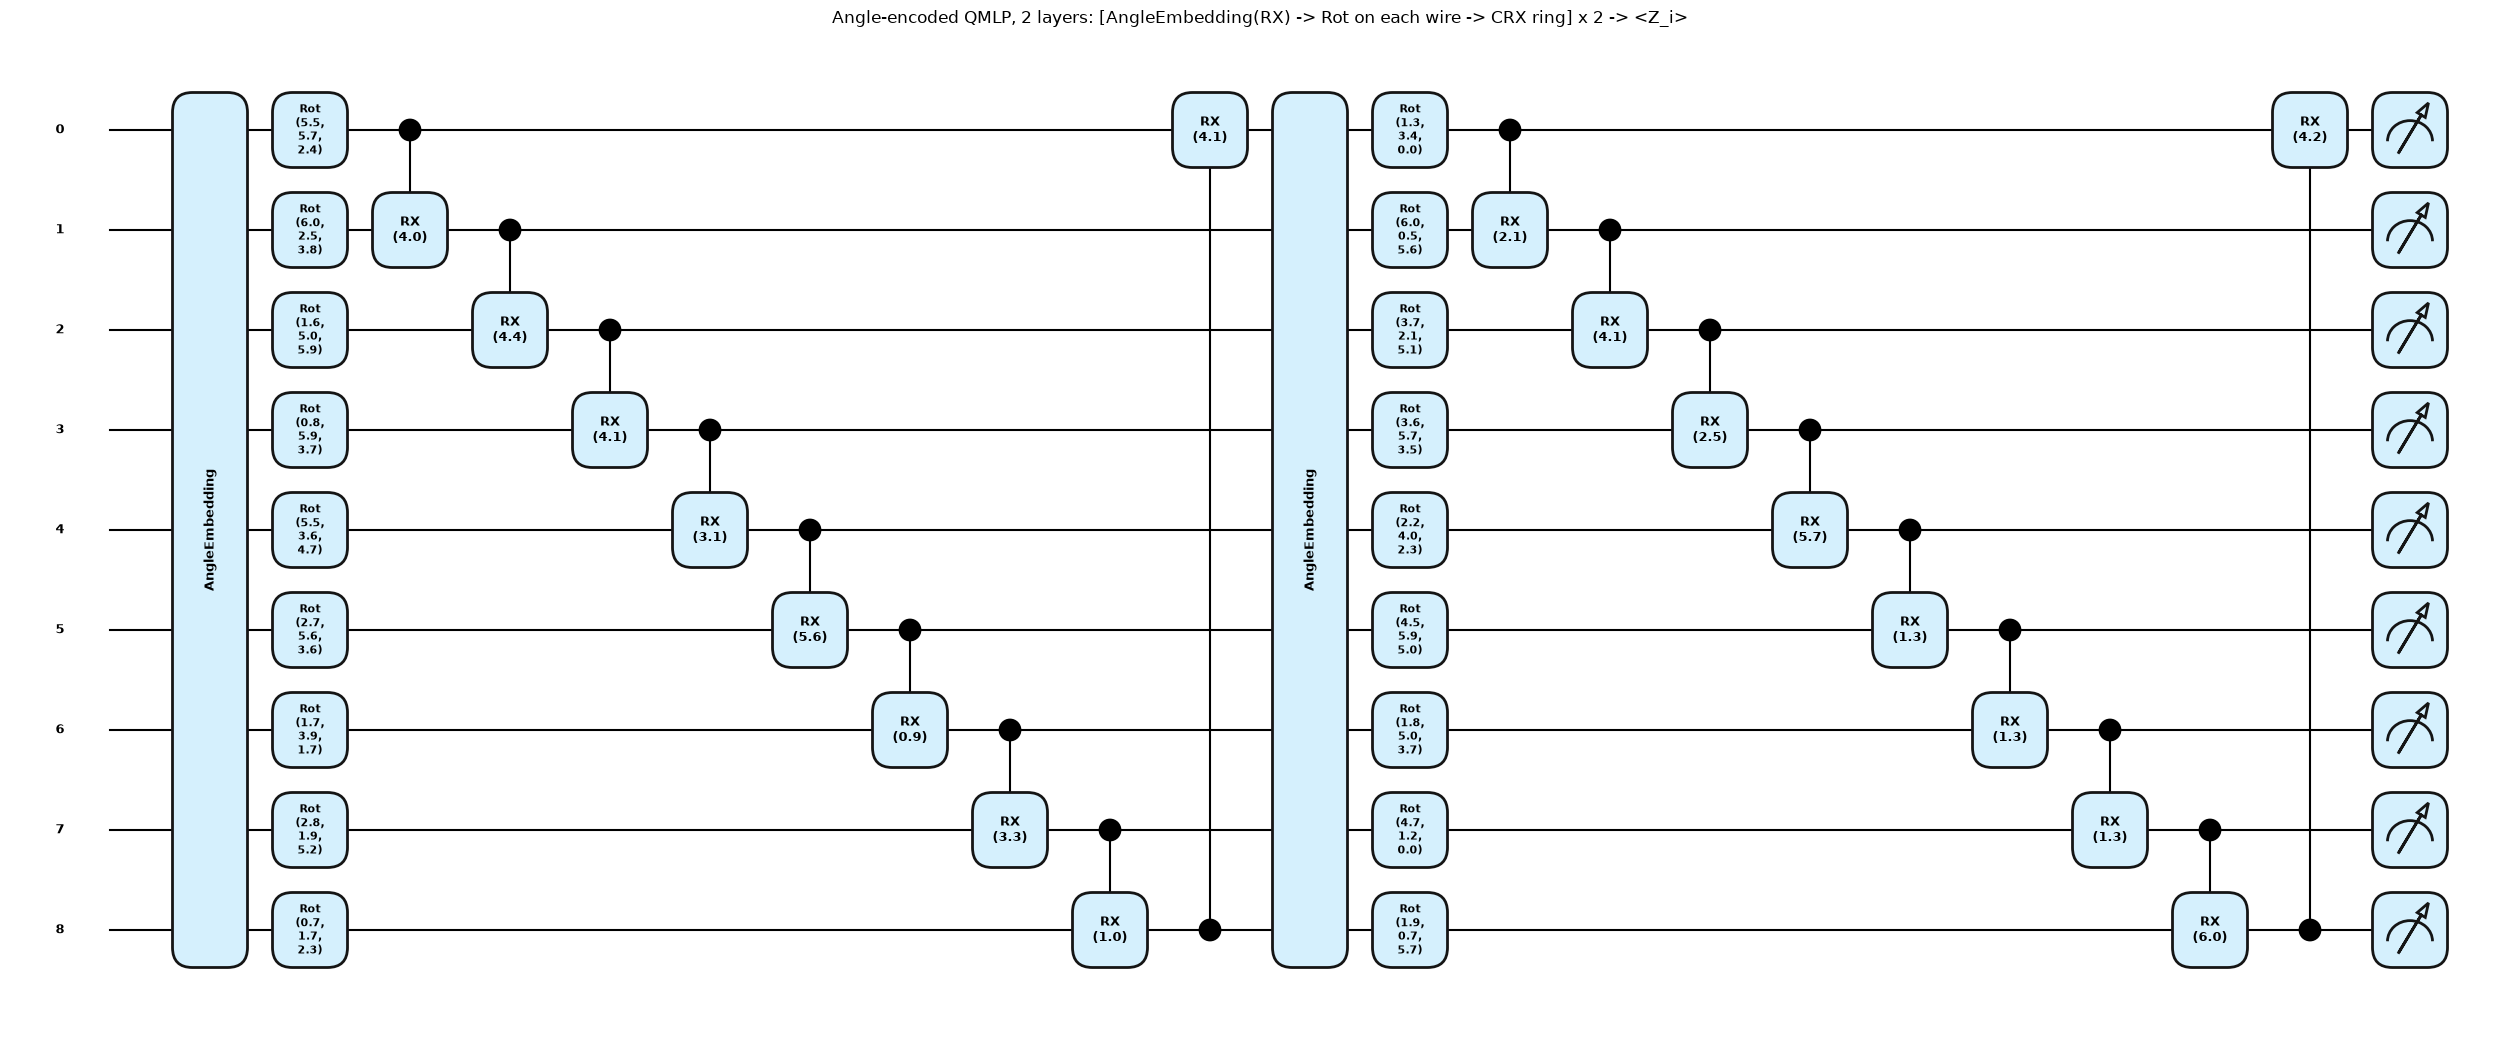

  qubits = 9,  depth = 22,  gates = 38,  trainable quantum parameters = 72 (2 layers x (9 Rot x 3 angles + 9 CRX x 1 angle)),  + classical head Linear(9 -> 10) = 100 parameters


  equivalence check: max |<Z_i> (torch simulator) - <Z_i> (PennyLane default.qubit)| = 1.5e-07  -> identical circuit
Architecture 2: QMLP with AMPLITUDE encoding (the 512 PCA components are loaded once), 2 layers


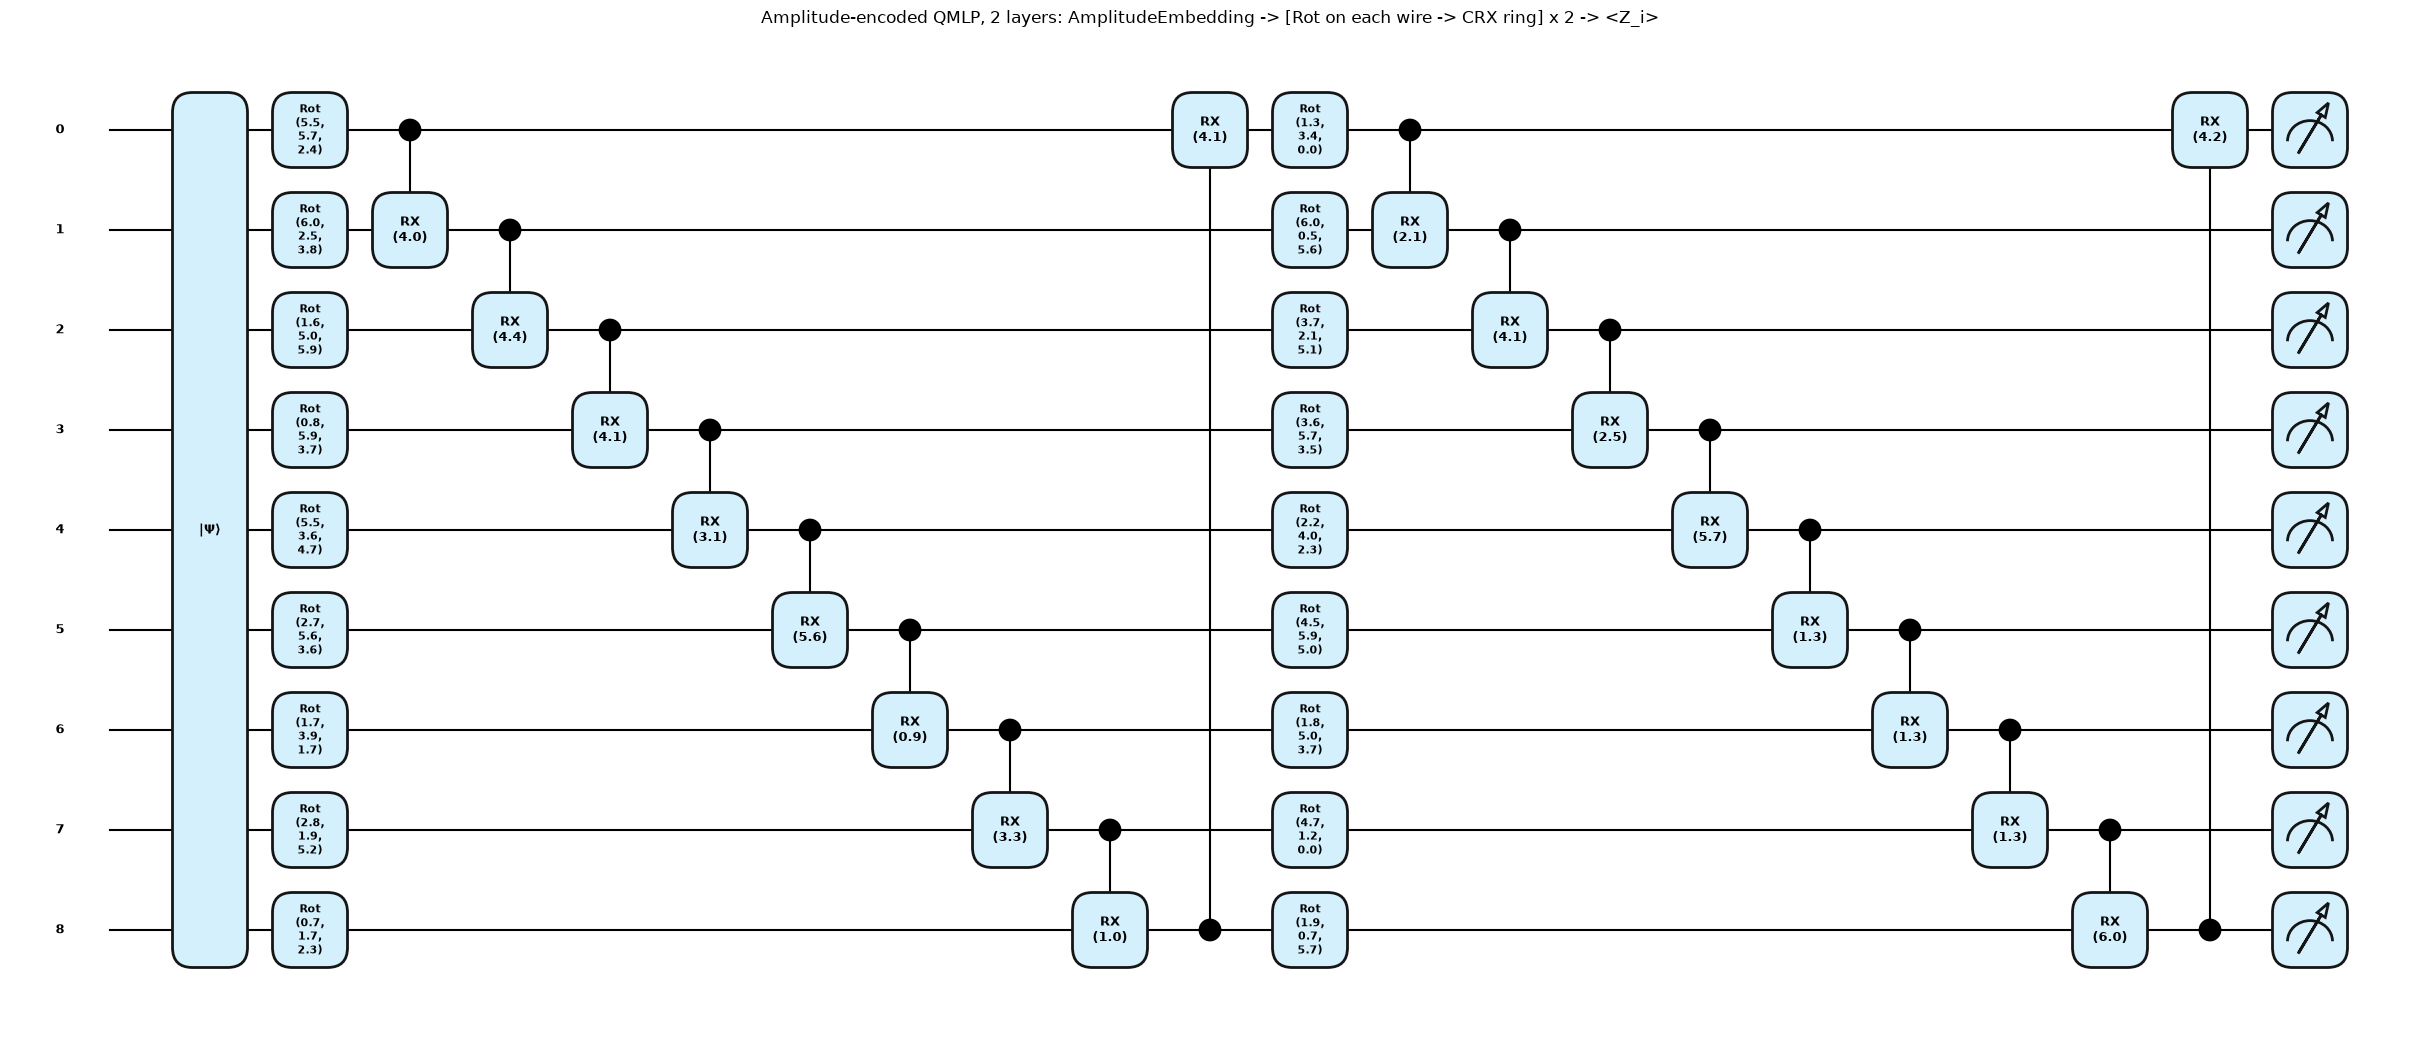

  qubits = 9,  depth = 21,  gates = 37,  trainable quantum parameters = 72 (2 layers x (9 Rot x 3 angles + 9 CRX x 1 angle)),  + classical head Linear(9 -> 10) = 100 parameters


  equivalence check: max |<Z_i> (torch simulator) - <Z_i> (PennyLane default.qubit)| = 2.1e-07  -> identical circuit
Architecture 3: angle-encoded QMLP with the QTrojan gate layers switched on (1 layer shown; the attack inserts the same layers in every layer)


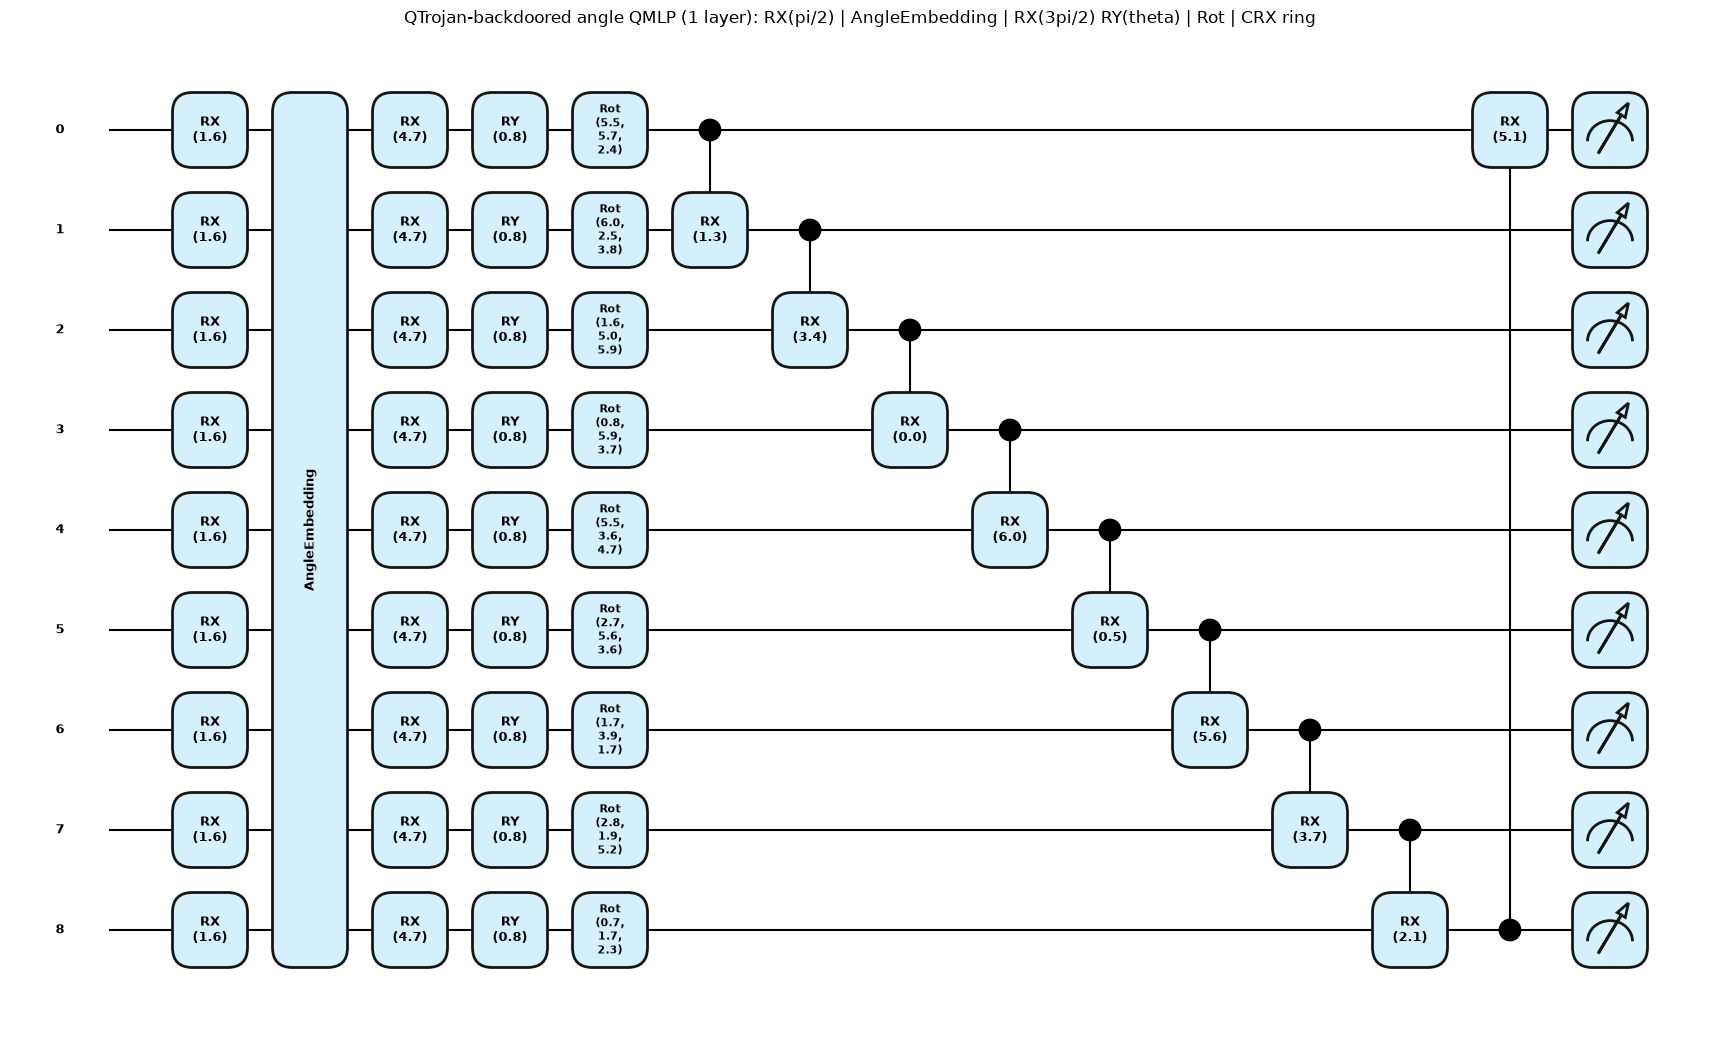

  qubits = 9,  depth = 14,  gates = 46,  trainable quantum parameters = 36 (1 layers x (9 Rot x 3 angles + 9 CRX x 1 angle)),  + classical head Linear(9 -> 10) = 100 parameters


  equivalence check: max |<Z_i> (torch simulator) - <Z_i> (PennyLane default.qubit)| = 1.1e-06  -> identical circuit
Deeper variants only repeat the bracketed block: parameters = 36 x layers quantum + (9 x classes + classes) classical.


In [7]:
def circuit_depth(tape):
    """Circuit depth = longest chain of gates that share a wire (every PennyLane operation counted once)."""
    d = {}
    for op in tape.operations:
        t = 1 + max([d.get(w, 0) for w in op.wires] + [0])
        for w in op.wires:
            d[w] = t
    return max(d.values())


def draw_and_check(enc, L, trojan=None, title="", n_check=3, n_classes=10):
    qn = make_pennylane_qnode(enc, L, trojan)
    g = torch.Generator().manual_seed(SEED)
    rot, crx = torch.rand(L, N_QUBITS, 3, generator=g) * 2 * math.pi, torch.rand(L, N_QUBITS, 1, generator=g) * 2 * math.pi
    x = torch.rand(N_QUBITS, generator=g) * 2 - 1 if enc == "angle" else torch.randn(512, generator=g)
    fig, ax = qml.draw_mpl(qn, decimals=1, style="pennylane", fontsize=9)(x, rot, crx)
    fig.suptitle(title, y=1.02); plt.show()
    tape = qml.workflow.construct_tape(qn)(x, rot, crx)
    n_params = L * N_QUBITS * 4
    print(f"  qubits = {N_QUBITS},  depth = {circuit_depth(tape)},  gates = {len(tape.operations)},  "
          f"trainable quantum parameters = {n_params} ({L} layers x (9 Rot x 3 angles + 9 CRX x 1 angle)),  "
          f"+ classical head Linear(9 -> {n_classes}) = {N_QUBITS * n_classes + n_classes} parameters")
    # equivalence: the torch simulator that trains the models == the PennyLane QNode drawn above
    m = QMLP(enc, L, n_classes)
    m.trojan = trojan
    with torch.no_grad():
        for p, v in zip(m.rot, rot): p.copy_(v)
        for p, v in zip(m.crx, crx): p.copy_(v)
    xs = torch.rand(n_check, N_QUBITS, generator=g) * 2 - 1 if enc == "angle" else torch.randn(n_check, 512, generator=g)
    with torch.no_grad():
        ours = m.quantum(xs)
    ref = torch.stack([torch.stack(list(qn(xs[b], rot, crx))) for b in range(n_check)]).float()
    err = float((ours - ref).abs().max())
    assert err < 1e-4, f"simulator differs from the PennyLane QNode: {err}"
    print(f"  equivalence check: max |<Z_i> (torch simulator) - <Z_i> (PennyLane default.qubit)| = {err:.1e}  -> identical circuit")


print("Architecture 1: QMLP with ANGLE encoding (re-uploading: the 9 features are re-encoded in every layer), 2 layers")
draw_and_check("angle", 2, None, "Angle-encoded QMLP, 2 layers: [AngleEmbedding(RX) -> Rot on each wire -> CRX ring] x 2 -> <Z_i>")
print("Architecture 2: QMLP with AMPLITUDE encoding (the 512 PCA components are loaded once), 2 layers")
draw_and_check("amplitude", 2, None, "Amplitude-encoded QMLP, 2 layers: AmplitudeEmbedding -> [Rot on each wire -> CRX ring] x 2 -> <Z_i>")
print("Architecture 3: angle-encoded QMLP with the QTrojan gate layers switched on (1 layer shown; the attack inserts the same layers in every layer)")
draw_and_check("angle", 1, TROJAN_THETA, "QTrojan-backdoored angle QMLP (1 layer): RX(pi/2) | AngleEmbedding | RX(3pi/2) RY(theta) | Rot | CRX ring")
print("Deeper variants only repeat the bracketed block: parameters = 36 x layers quantum + (9 x classes + classes) classical.")


## 4. Training recipe and helpers

* CMLP: `Linear(in, 128) - ReLU - Dropout(0.5) - Linear(128, 64) - ReLU - Dropout(0.5) - Linear(64, classes)` (the layout of the authors' classical scripts).
* All models: Adam (weight decay 1e-4), batch 64, negative log-likelihood, optional label smoothing, optional Q-Detection sample weights.
* Model selection: the epoch with the best accuracy on a **clean validation split** drawn from the training pool (disjoint from the training subset and from the test set). The authors selected on the test set; we do not
  (an honest deviation that can only lower our numbers slightly).  All transforms (MinMax, PCA) were fitted on the training pool only.

In [8]:
class CMLP(nn.Module):
    """Classical baseline of the paper: MLP with the same training recipe (784/2439 -> 128 -> 64 -> classes, dropout 0.5)."""
    def __init__(self, d_in, n_classes):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, 128), nn.ReLU(), nn.Dropout(0.5),
                                 nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.5), nn.Linear(64, n_classes))

    def forward(self, x):
        return F.log_softmax(self.net(x), dim=1)


def make_split(D, seed, per_class, val_per_class, test_n):
    """Class-balanced train subset + disjoint clean validation split from the training pool; random test subset."""
    rng = np.random.default_rng(seed)
    tr, va = [], []
    for c in range(D["n_classes"]):
        idx = rng.permutation(np.where(D["y_tr"] == c)[0])
        k = min(per_class, max(1, len(idx) - val_per_class))
        tr.append(idx[:k]); va.append(idx[k:k + val_per_class])
    tr, va = rng.permutation(np.concatenate(tr)), np.concatenate(va)
    te = rng.choice(len(D["y_te"]), size=min(test_n, len(D["y_te"])), replace=False)
    return tr, va, te


def T(a, dtype=torch.float32):
    return torch.as_tensor(np.asarray(a), dtype=dtype)


@torch.no_grad()
def predict(model, X, bs=256):
    model.eval()
    return torch.cat([model(X[i:i + bs]).argmax(1) for i in range(0, len(X), bs)])


def accuracy(model, X, y):
    return float((predict(model, X) == y).float().mean())


def train_model(model, X, y, Xva, yva, epochs, lr, seed, smoothing=0.0, qwan=None, qd_steps=1, log=None):
    """Adam training (batch 64, weight decay).  The epoch with the best accuracy on the CLEAN validation split is kept
    (the authors kept the epoch with the best TEST accuracy; we do not touch the test set).
    smoothing > 0: label smoothing; qwan: Q-Detection bank (per-sample weights from the Ising model)."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    n, K = len(X), model(X[:1]).shape[1]
    best, best_state, hist = -1.0, None, []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=g)
        tot = 0.0
        for i in range(0, n, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            xb, yb = X[idx], y[idx]
            logp = model(xb)
            per = -logp.gather(1, yb[:, None])[:, 0]
            if smoothing > 0:
                per = (1 - smoothing) * per + smoothing * (-logp.mean(1))
            if qwan is not None:
                lv = per.detach().numpy()
                for _ in range(qd_steps):
                    qwan.train_step(idx.numpy(), lv)
                w = torch.as_tensor(qwan.weights(idx.numpy(), lv), dtype=torch.float32).clamp_min(1e-12)
                loss = (w * per).sum() / w.sum()
            else:
                loss = per.mean()
            opt.zero_grad(); loss.backward(); opt.step()
            tot += float(loss) * len(idx)
        va = accuracy(model, Xva, yva)
        hist.append((ep + 1, tot / n, va))
        if va >= best:
            best, best_state = va, {k: v.clone() for k, v in model.state_dict().items()}
        if log:
            print(f"    {log} epoch {ep + 1:>2}/{epochs}  loss {tot / n:.3f}  val acc {va:.3f}", flush=True)
    model.load_state_dict(best_state)
    return hist


def new_model(kind, D, seed):
    """kind: 'cmlp' | 'angle:L' | 'amp:L'.  Returns (model, input-matrix key)."""
    torch.manual_seed(seed)
    if kind == "cmlp":
        return CMLP(D["Xc_tr"].shape[1], D["n_classes"]), "Xc"
    enc, L = kind.split(":")
    return QMLP("angle" if enc == "angle" else "amplitude", int(L), D["n_classes"]), ("A" if enc == "angle" else "M")


def run_one(kind, D, tr, va, te, seed, y_train=None, epochs=None, lr=None, smoothing=0.0, X_train=None, qwan=None, qd_steps=1, log=None):
    """Train one model of the given kind on the split; returns dict(model, acc (test), key, secs)."""
    model, key = new_model(kind, D, seed)
    epochs = epochs or (EPOCHS_C if kind == "cmlp" else EPOCHS_Q)
    lr = lr or (LR_C if kind == "cmlp" else LR_Q)
    Xall, Xte_all = D[key + "_tr"], D[key + "_te"]
    Xtr = T(Xall[tr]) if X_train is None else T(X_train)
    ytr = T(D["y_tr"][tr] if y_train is None else y_train, torch.long)
    t0 = time.time()
    train_model(model, Xtr, ytr, T(Xall[va]), T(D["y_tr"][va], torch.long), epochs, lr, seed, smoothing, qwan, qd_steps, log)
    acc = accuracy(model, T(Xte_all[te]), T(D["y_te"][te], torch.long))
    return dict(model=model, acc=acc, key=key, secs=time.time() - t0)


def mean_std(v):
    v = np.asarray(v, dtype=float)
    return float(v.mean()), float(v.std())


## 5. Baselines (Table 2) and classical models on identical inputs

Each model type is trained on the class-balanced subset and tested on a held-out random test subset.  The table prints the notebook's subset accuracy ("S") next to the paper's "S" and "F" values.
RandomForest and SVC(rbf) get exactly the same reduced inputs as the quantum models (9-D angle features, or the 512-D amplitude features normalised like the quantum state).

In [9]:
PAPER_T2 = {   # Table 2, noiseless columns (F = full data, S = stratified subset); percent
    ("AZ", "angle", 2): (49.8, 46.0), ("AZ", "angle", 5): (52.3, 47.1), ("AZ", "angle", 10): (54.8, 48.7), ("AZ", "angle", 50): (32.4, 28.6),
    ("AZ", "amp", 2): (40.1, 34.3), ("AZ", "amp", 5): (48.1, 42.1), ("AZ", "amp", 10): (55.0, 45.7), ("AZ", "amp", 50): (67.0, 55.7),
    ("MNIST", "angle", 2): (66.0, 41.9), ("MNIST", "angle", 5): (68.0, 53.9), ("MNIST", "angle", 10): (83.6, 55.8), ("MNIST", "angle", 50): (76.9, 52.4),
    ("MNIST", "amp", 2): (50.7, 45.5), ("MNIST", "amp", 5): (70.3, 52.9), ("MNIST", "amp", 10): (79.8, 60.82), ("MNIST", "amp", 50): (92.6, 84.3),
    ("AZ", "cmlp", 0): (95.89, None), ("MNIST", "cmlp", 0): (96.63, None),
}
KINDS = ["cmlp"] + [f"angle:{L}" for L in LAYERS_ANGLE] + [f"amp:{L}" for L in LAYERS_AMP]
SPLITS, BASE = {}, {}          # BASE[(dataset, kind, seed_index)] -> result dict (model, test accuracy, ...)

for name in DATASETS:
    D = DATA[name]
    for s in range(N_SEEDS):
        SPLITS[(name, s)] = make_split(D, SEED + s, SUB_PER_CLASS, VAL_PER_CLASS, TEST_N)
        tr, va, te = SPLITS[(name, s)]
        for kind in KINDS:
            r = run_one(kind, D, tr, va, te, SEED + s)
            BASE[(name, kind, s)] = r
            print(f"[{name}] subset baseline  {kind:<9} seed {s}: test accuracy {100 * r['acc']:.1f}%   (train {len(tr)} samples, {r['secs']:.0f}s)", flush=True)

# --- classical baselines on the IDENTICAL reduced inputs (RandomForest, SVC rbf) -----------------------------------
rows = []
for name in DATASETS:
    D = DATA[name]
    tr, va, te = SPLITS[(name, 0)]
    for key, label in [("A", "9-D angle input"), ("M", "512-D amplitude input")]:
        Xtr, Xte = D[key + "_tr"][tr], D[key + "_te"][te]
        if key == "M":
            Xtr, Xte = Xtr / np.linalg.norm(Xtr, axis=1, keepdims=True), Xte / np.linalg.norm(Xte, axis=1, keepdims=True)   # the state the circuit sees
        rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=N_THREADS).fit(Xtr, D["y_tr"][tr])
        sv = SVC(kernel="rbf", C=1.0, gamma="scale").fit(Xtr, D["y_tr"][tr])
        rows.append((name, label, 100 * rf.score(Xte, D["y_te"][te]), 100 * sv.score(Xte, D["y_te"][te])))
sk = pd.DataFrame(rows, columns=["dataset", "identical input", "RandomForest %", "SVC-rbf %"]).round(1)
print("\nClassical models on exactly the inputs of the quantum models (same train/test subset):")
print(sk.to_string(index=False))

# --- Table 2 side by side (noiseless) ---------------------------------------------------------------------------
rows = []
for name in DATASETS:
    for kind in KINDS:
        accs = [100 * BASE[(name, kind, s)]["acc"] for s in range(N_SEEDS)]
        m, sd = mean_std(accs)
        enc, L = ("cmlp", 0) if kind == "cmlp" else (kind.split(":")[0], int(kind.split(":")[1]))
        pf, ps = PAPER_T2.get((name, enc, L), (None, None))
        rows.append(dict(dataset=name, model=kind, **{"notebook S acc % (mean)": round(m, 1), "std": round(sd, 1),
                         "paper S %": ps, "paper F %": pf}))
T2 = pd.DataFrame(rows)
print("\nTable 2 (noiseless): subset ('S') accuracies, notebook vs paper.  Paper 'S' = 700 samples/class, 30 epochs; this run = %d samples/class, %d epochs." % (SUB_PER_CLASS, EPOCHS_Q))
print(T2.to_string(index=False))


[MNIST] subset baseline  cmlp      seed 0: test accuracy 84.1%   (train 1000 samples, 30s)


[MNIST] subset baseline  angle:2   seed 0: test accuracy 51.6%   (train 1000 samples, 53s)


[MNIST] subset baseline  amp:2     seed 0: test accuracy 40.4%   (train 1000 samples, 73s)


[AZ] subset baseline  cmlp      seed 0: test accuracy 65.7%   (train 2300 samples, 17s)


[AZ] subset baseline  angle:2   seed 0: test accuracy 44.8%   (train 2300 samples, 57s)


[AZ] subset baseline  amp:2     seed 0: test accuracy 31.1%   (train 2300 samples, 65s)



Classical models on exactly the inputs of the quantum models (same train/test subset):
dataset       identical input  RandomForest %  SVC-rbf %
  MNIST       9-D angle input            67.2       71.0
  MNIST 512-D amplitude input            82.0       91.4
     AZ       9-D angle input            61.2       54.1
     AZ 512-D amplitude input            72.1       75.0

Table 2 (noiseless): subset ('S') accuracies, notebook vs paper.  Paper 'S' = 700 samples/class, 30 epochs; this run = 100 samples/class, 8 epochs.
dataset   model  notebook S acc % (mean)  std  paper S %  paper F %
  MNIST    cmlp                     84.1  0.0        NaN      96.63
  MNIST angle:2                     51.6  0.0       41.9      66.00
  MNIST   amp:2                     40.4  0.0       45.5      50.70
     AZ    cmlp                     65.7  0.0        NaN      95.89
     AZ angle:2                     44.8  0.0       46.0      49.80
     AZ   amp:2                     31.1  0.0       34.3      40.10


### 5b. "Full data" accuracies (Table 2, F columns)

The CMLP is trained on the whole training pool (MNIST: 60,000 images).  QMLP "F" runs (up to `FULL_TRAIN_CAP` rows) are only done in the full configuration because the simulator is the bottleneck.

In [10]:
FULLRES = {}     # (dataset, kind) -> test accuracy (%) trained on (a large part of) the whole training pool ("F" columns of Table 2)
for name in DATASETS:
    D = DATA[name]
    rng = np.random.default_rng(SEED)
    perm = rng.permutation(len(D["y_tr"]))
    n_val = min(5000, len(perm) // 20)
    va_all, tr_all = perm[:n_val], perm[n_val:]
    te_all = np.arange(len(D["y_te"]))
    jobs = [("cmlp", tr_all, CMLP_FULL_EPOCHS)]
    if FULL_TRAIN_CAP:
        jobs += [(f"angle:{LAYERS_ANGLE[0]}", tr_all[:FULL_TRAIN_CAP], EPOCHS_Q), (f"amp:{LAYERS_AMP[0]}", tr_all[:FULL_TRAIN_CAP], EPOCHS_Q)]
    for kind, tr_idx, ep in jobs:
        r = run_one(kind, D, tr_idx, va_all, te_all, SEED, epochs=ep)
        FULLRES[(name, kind)] = 100 * r["acc"]
        print(f"[{name}] 'full data' {kind:<9}: trained on {len(tr_idx)} samples for {ep} epochs -> accuracy on {len(te_all)} test samples = {100 * r['acc']:.2f}%  ({r['secs']:.0f}s)", flush=True)
print("\nPaper (Table 2, F columns): CMLP 96.63% (MNIST) / 95.89% (AZ-Class);  QMLP-angle 2 layers 66.0% / 49.8%;  QMLP-amplitude 2 layers 50.7% / 40.1%")
if not FULL_TRAIN_CAP:
    print("(QMLP 'F' runs are skipped in FAST mode: the quantum simulator is the bottleneck; only the classical MLP is trained on the whole pool.)")


[MNIST] 'full data' cmlp     : trained on 57000 samples for 3 epochs -> accuracy on 10000 test samples = 95.84%  (1344s)


[AZ] 'full data' cmlp     : trained on 22800 samples for 3 epochs -> accuracy on 2000 test samples = 78.10%  (1100s)



Paper (Table 2, F columns): CMLP 96.63% (MNIST) / 95.89% (AZ-Class);  QMLP-angle 2 layers 66.0% / 49.8%;  QMLP-amplitude 2 layers 50.7% / 40.1%
(QMLP 'F' runs are skipped in FAST mode: the quantum simulator is the bottleneck; only the classical MLP is trained on the whole pool.)


## 6. Black-box poisoning: 50 % label flipping (Table 3)

An adversary replaces the label of a random 50 % of the training samples by a random wrong label (features untouched).  *Relative accuracy* = accuracy of the attacked model / accuracy of the clean model of the same type.
Label smoothing (alpha = 0.2) is the defence.  The paper's explanation for the QMLP's high ratio is a *ceiling effect* (low clean accuracy leaves little to lose) plus the regularising effect of the PCA reduction, not true quantum robustness - the table lets you judge.

**Audit control.** The authors' released classical script (`Classical ML/mnist-mlp-label-flipping.py`) does not train on poisoned data: it loads the *clean* CMLP checkpoint and evaluates it on a test set in which a random 50 % of the labels were shifted to `(y + 1) mod 10`.
That mechanically halves the accuracy, i.e. it produces a relative accuracy of about 0.50 without any attack on training. The cell below reproduces that number as a control next to a genuine training-time attack on the CMLP.

[MNIST] label flipping 50% cmlp      smoothing=0   seed 0: acc 69.6%  relative accuracy 0.83


[MNIST] label flipping 50% cmlp      smoothing=0.2 seed 0: acc 68.6%  relative accuracy 0.82


[MNIST] label flipping 50% angle:2   smoothing=0   seed 0: acc 41.6%  relative accuracy 0.81


[MNIST] label flipping 50% angle:2   smoothing=0.2 seed 0: acc 40.1%  relative accuracy 0.78


[MNIST] label flipping 50% amp:2     smoothing=0   seed 0: acc 33.0%  relative accuracy 0.82


[MNIST] label flipping 50% amp:2     smoothing=0.2 seed 0: acc 34.7%  relative accuracy 0.86



Table 3 (noiseless): relative accuracy = accuracy under 50% label flipping / clean accuracy of the same model type
dataset   model  ratio LS=N  paper LS=N  ratio LS=Y  paper LS=Y
  MNIST    cmlp        0.83        0.50        0.82        0.51
  MNIST angle:2        0.81        0.93        0.78        0.92
  MNIST   amp:2        0.82        1.03        0.86        1.06


[MNIST] CMLP 'label flipping' as implemented in the released script (clean model, 50% of the TEST labels shifted): relative accuracy 0.50   vs. a real training-time attack on the CMLP (above): 0.83   (paper: 0.5)


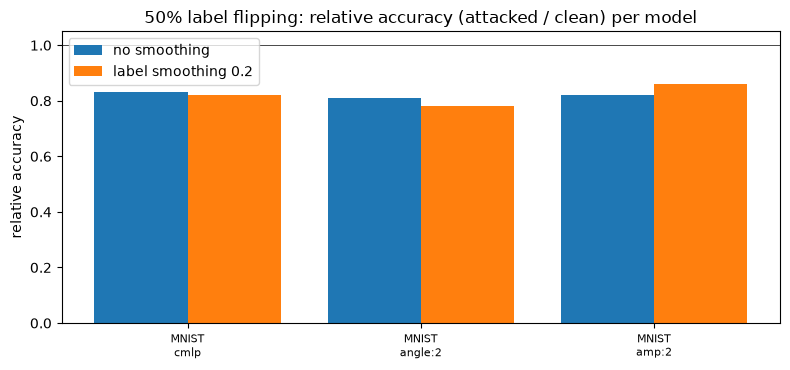

In [11]:
PAPER_T3 = {   # Table 3, noiseless columns (relative accuracy ratios); key (dataset, kind, label smoothing)
    ("AZ", "cmlp", "N"): 0.51, ("AZ", "cmlp", "Y"): 0.59, ("MNIST", "cmlp", "N"): 0.50, ("MNIST", "cmlp", "Y"): 0.51,
    ("AZ", "angle:2", "N"): 0.93, ("AZ", "angle:5", "N"): 0.91, ("AZ", "angle:10", "N"): 0.91,
    ("AZ", "angle:2", "Y"): 0.90, ("AZ", "angle:5", "Y"): 0.91, ("AZ", "angle:10", "Y"): 0.89,
    ("MNIST", "angle:2", "N"): 0.93, ("MNIST", "angle:5", "N"): 0.95, ("MNIST", "angle:10", "N"): 0.79,
    ("MNIST", "angle:2", "Y"): 0.92, ("MNIST", "angle:5", "Y"): 0.95, ("MNIST", "angle:10", "Y"): 0.79,
    ("AZ", "amp:2", "N"): 0.94, ("AZ", "amp:10", "N"): 0.92, ("AZ", "amp:50", "N"): 0.93,
    ("AZ", "amp:2", "Y"): 0.87, ("AZ", "amp:10", "Y"): 0.91, ("AZ", "amp:50", "Y"): 0.90,
    ("MNIST", "amp:2", "N"): 1.03, ("MNIST", "amp:10", "N"): 0.95, ("MNIST", "amp:50", "N"): 0.97,
    ("MNIST", "amp:2", "Y"): 1.06, ("MNIST", "amp:10", "Y"): 0.98, ("MNIST", "amp:50", "Y"): 0.97,
}
# NOTE on Table 3's garbled extraction: the AccNL / AccDN columns come in pairs per dataset; the MNIST noiseless column of the angle rows
# reads 0.93 / 0.95 / 0.79 (2/5/10 layers) and the AZ noiseless column 0.93 / 0.91 / 0.91 - we use the noiseless (first) column of each dataset.


def flip_labels(y, K, frac, seed):
    """Untargeted label flipping: a random `frac` of the labels is replaced by a uniformly drawn WRONG label."""
    rng = np.random.default_rng(seed)
    y2 = y.copy()
    idx = rng.choice(len(y), size=int(round(frac * len(y))), replace=False)
    for i in idx:
        y2[i] = rng.choice([c for c in range(K) if c != y[i]])
    return y2, idx


LF = {}      # (dataset, kind, smoothing, seed) -> relative accuracy
for name in ATTACK_DATASETS:
    if name not in DATA:
        continue
    D = DATA[name]
    for s in range(N_SEEDS):
        tr, va, te = SPLITS[(name, s)]
        y_flip, _ = flip_labels(D["y_tr"][tr], D["n_classes"], LF_RATIO, SEED + 100 + s)
        for kind in KINDS:
            for sm in (0.0, SMOOTHING):
                r = run_one(kind, D, tr, va, te, SEED + s, y_train=y_flip, smoothing=sm)
                base = BASE[(name, kind, s)]["acc"]
                LF[(name, kind, "Y" if sm else "N", s)] = (r["acc"] / base, 100 * r["acc"])
                print(f"[{name}] label flipping 50% {kind:<9} smoothing={'0.2' if sm else '0  '} seed {s}: acc {100 * r['acc']:.1f}%  "
                      f"relative accuracy {r['acc'] / base:.2f}", flush=True)

rows = []
for name in ATTACK_DATASETS:
    if name not in DATA:
        continue
    for kind in KINDS:
        row = dict(dataset=name, model=kind)
        for ls in ("N", "Y"):
            m, sd = mean_std([LF[(name, kind, ls, s)][0] for s in range(N_SEEDS)])
            row[f"ratio LS={ls}"] = round(m, 2)
            row[f"paper LS={ls}"] = PAPER_T3.get((name, kind, ls))
        rows.append(row)
T3 = pd.DataFrame(rows)
print("\nTable 3 (noiseless): relative accuracy = accuracy under 50% label flipping / clean accuracy of the same model type")
print(T3.to_string(index=False))

# --- control: what the authors' RELEASED classical script ("Classical ML/mnist-mlp-label-flipping.py") actually evaluates -----------
# It loads the CLEAN CMLP checkpoint and tests it on a test set whose labels were shifted ((y + 1) mod 10) for a random 50 % of the samples.
# That is not a training-time attack; the accuracy drops by ~50 % by construction.
LF_RELEASED = {}
for name in ATTACK_DATASETS:
    if name not in DATA:
        continue
    D = DATA[name]
    tr, va, te = SPLITS[(name, 0)]
    clean_model = BASE[(name, "cmlp", 0)]["model"]
    pred = predict(clean_model, T(D["Xc_te"][te])).numpy()
    y = D["y_te"][te]
    flip = np.random.default_rng(SEED + 7).random(len(y)) < LF_RATIO
    y_shifted = np.where(flip, (y + 1) % D["n_classes"], y)
    LF_RELEASED[name] = float((pred == y_shifted).mean()) / BASE[(name, "cmlp", 0)]["acc"]
    print(f"[{name}] CMLP 'label flipping' as implemented in the released script (clean model, 50% of the TEST labels shifted): "
          f"relative accuracy {LF_RELEASED[name]:.2f}   vs. a real training-time attack on the CMLP (above): "
          f"{mean_std([LF[(name, 'cmlp', 'N', s)][0] for s in range(N_SEEDS)])[0]:.2f}   (paper: {PAPER_T3[(name, 'cmlp', 'N')]})")
fig, ax = plt.subplots(figsize=(8, 3.8))
lab = [f"{r.dataset}\n{r.model}" for r in T3.itertuples()]
xs = np.arange(len(T3)); ax.bar(xs - 0.2, T3["ratio LS=N"], 0.4, label="no smoothing"); ax.bar(xs + 0.2, T3["ratio LS=Y"], 0.4, label="label smoothing 0.2")
ax.set_xticks(xs); ax.set_xticklabels(lab, fontsize=8); ax.axhline(1, color="k", lw=0.5); ax.set_ylabel("relative accuracy"); ax.legend()
ax.set_title("50% label flipping: relative accuracy (attacked / clean) per model")
plt.tight_layout(); plt.show()


## 7. Gray-box poisoning: QUID and the Q-Detection defence (Tables 4-5)

QUID relabels a fraction epsilon of the training samples with the class whose **prototype density matrix** is farthest (Frobenius distance) from the sample's own encoded density matrix; it only needs the *encoding circuit*.
For pure states this has a closed form, ||rho_x - rho_c||^2 = 1 - 2 <x|rho_c|x> + tr(rho_c^2) with rho_c = mean_j |psi_j><psi_j|, so no 512 x 512 matrix is needed.  **ASR** = share of the poisoned training samples that the
final model assigns to their *poisoned* label.  Q-Detection learns per-sample weights from an Ising model (simulated annealing) and down-weights likely-poisoned samples.

[MNIST] QUID angle:2   poison 0.1              seed 0: labels changed 99/100  acc 33.7%  rel.acc 0.65  ASR 4.0%  (400s)


[MNIST] QUID angle:2   poison 0.3              seed 0: labels changed 292/300  acc 13.7%  rel.acc 0.27  ASR 49.7%  (488s)


[MNIST] QUID angle:2   poison 0.3 +Q-Detection seed 0: labels changed 292/300  acc 10.6%  rel.acc 0.21  ASR 48.0%  (806s)


[MNIST] QUID angle:2   poison 0.5              seed 0: labels changed 489/500  acc 1.3%  rel.acc 0.03  ASR 89.0%  (738s)


[MNIST] QUID amp:2     poison 0.1              seed 0: labels changed 99/100  acc 43.1%  rel.acc 1.07  ASR 14.0%  (511s)


[MNIST] QUID amp:2     poison 0.3              seed 0: labels changed 299/300  acc 24.5%  rel.acc 0.61  ASR 62.0%  (538s)


[MNIST] QUID amp:2     poison 0.3 +Q-Detection seed 0: labels changed 299/300  acc 21.1%  rel.acc 0.52  ASR 65.7%  (423s)


[MNIST] QUID amp:2     poison 0.5              seed 0: labels changed 497/500  acc 12.1%  rel.acc 0.30  ASR 83.6%  (224s)



Tables 4-5 (noiseless): QUID relative accuracy and attack success rate (%) without / with Q-Detection
dataset   model  ratio  relacc_wo  paper_relacc_wo  relacc_with_QD  paper_relacc_with  ASR_wo  paper_ASR_wo  ASR_with_QD  paper_ASR_with
  MNIST angle:2    0.1       0.65             0.69             NaN               0.65    4.00          3.00          NaN            2.76
  MNIST angle:2    0.3       0.27             0.23            0.21               0.35   49.67         52.30        48.00           38.49
  MNIST angle:2    0.5       0.03             0.22             NaN               0.21   89.00         53.64          NaN           54.72
  MNIST   amp:2    0.1       1.07             0.56             NaN               0.70   14.00         59.62          NaN           23.38
  MNIST   amp:2    0.3       0.61             0.29            0.52               0.33   62.00         75.79        65.67           64.16
  MNIST   amp:2    0.5       0.30             0.26             NaN         

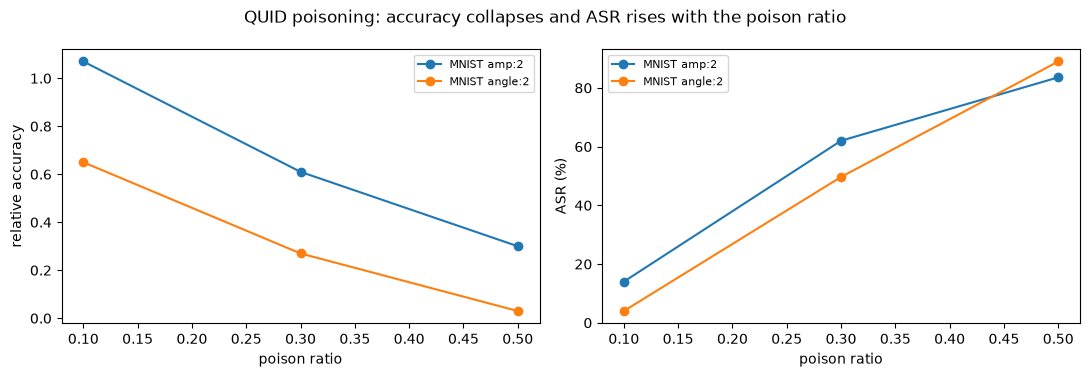

In [12]:
PAPER_T4 = {   # Table 4 relative accuracy, noiseless (w/o, w/ Q-Detection); key (dataset, enc, L, ratio)
    ("AZ", "amp", 2, 0.1): (0.49, 0.57), ("AZ", "amp", 2, 0.3): (0.30, 0.34), ("AZ", "amp", 2, 0.5): (0.21, 0.30),
    ("AZ", "amp", 10, 0.1): (0.53, 0.57), ("AZ", "amp", 10, 0.3): (0.25, 0.35), ("AZ", "amp", 10, 0.5): (0.12, 0.16),
    ("MNIST", "amp", 2, 0.1): (0.56, 0.70), ("MNIST", "amp", 2, 0.3): (0.29, 0.33), ("MNIST", "amp", 2, 0.5): (0.26, 0.28),
    ("MNIST", "amp", 10, 0.1): (0.63, 0.75), ("MNIST", "amp", 10, 0.3): (0.21, 0.39), ("MNIST", "amp", 10, 0.5): (0.19, 0.19),
    ("AZ", "angle", 2, 0.1): (0.72, 0.76), ("AZ", "angle", 2, 0.3): (0.24, 0.45), ("AZ", "angle", 2, 0.5): (0.11, 0.16),
    ("AZ", "angle", 5, 0.1): (0.83, 0.82), ("AZ", "angle", 5, 0.3): (0.40, 0.62), ("AZ", "angle", 5, 0.5): (0.11, 0.21),
    ("AZ", "angle", 10, 0.1): (0.78, 0.75), ("AZ", "angle", 10, 0.3): (0.38, 0.60), ("AZ", "angle", 10, 0.5): (0.10, 0.20),
    ("MNIST", "angle", 2, 0.1): (0.69, 0.65), ("MNIST", "angle", 2, 0.3): (0.23, 0.35), ("MNIST", "angle", 2, 0.5): (0.22, 0.21),
    ("MNIST", "angle", 5, 0.1): (0.74, 0.69), ("MNIST", "angle", 5, 0.3): (0.18, 0.39), ("MNIST", "angle", 5, 0.5): (0.18, 0.18),
    ("MNIST", "angle", 10, 0.1): (0.80, 0.75), ("MNIST", "angle", 10, 0.3): (0.20, 0.47), ("MNIST", "angle", 10, 0.5): (0.19, 0.19),
}
PAPER_T5 = {   # Table 5 attack success rate (%), noiseless (w/o, w/ Q-Detection)
    ("AZ", "amp", 2, 0.1): (70.50, 58.12), ("AZ", "amp", 2, 0.3): (88.12, 85.58), ("AZ", "amp", 2, 0.5): (91.49, 88.94),
    ("AZ", "amp", 10, 0.1): (56.54, 42.90), ("AZ", "amp", 10, 0.3): (87.03, 79.05), ("AZ", "amp", 10, 0.5): (93.15, 91.53),
    ("MNIST", "amp", 2, 0.1): (59.62, 23.38), ("MNIST", "amp", 2, 0.3): (75.79, 64.16), ("MNIST", "amp", 2, 0.5): (82.02, 77.66),
    ("MNIST", "amp", 10, 0.1): (37.90, 12.00), ("MNIST", "amp", 10, 0.3): (85.13, 56.03), ("MNIST", "amp", 10, 0.5): (87.08, 86.73),
    ("AZ", "angle", 2, 0.1): (16.25, 9.79), ("AZ", "angle", 2, 0.3): (76.87, 42.98), ("AZ", "angle", 2, 0.5): (88.83, 82.04),
    ("AZ", "angle", 5, 0.1): (11.29, 7.58), ("AZ", "angle", 5, 0.3): (68.37, 33.43), ("AZ", "angle", 5, 0.5): (85.26, 69.48),
    ("AZ", "angle", 10, 0.1): (14.51, 10.12), ("AZ", "angle", 10, 0.3): (69.31, 30.57), ("AZ", "angle", 10, 0.5): (87.11, 78.50),
    ("MNIST", "angle", 2, 0.1): (3.00, 2.76), ("MNIST", "angle", 2, 0.3): (52.30, 38.49), ("MNIST", "angle", 2, 0.5): (53.64, 54.72),
    ("MNIST", "angle", 5, 0.1): (3.90, 2.90), ("MNIST", "angle", 5, 0.3): (54.70, 8.02), ("MNIST", "angle", 5, 0.5): (53.99, 54.93),
    ("MNIST", "angle", 10, 0.1): (3.52, 5.62), ("MNIST", "angle", 10, 0.3): (62.22, 16.16), ("MNIST", "angle", 10, 0.5): (48.98, 48.80),
}


def encoder_states(kind, X):
    """The quantum states |psi(x)> produced by the ENCODING layer alone (this is all QUID needs)."""
    X = T(X)
    with torch.no_grad():
        return angle_embed(zero_state(len(X)), X) if kind.startswith("angle") else amplitude_embed(X)


def quid_labels(kind, X, y, K, idx):
    """QUID (Kundu & Ghosh): relabel the selected samples with the class whose PROTOTYPE density matrix is farthest (Frobenius distance)
    from the sample's own encoded density matrix.  ||rho_x - rho_c||^2 = 1 - 2 <x|rho_c|x> + tr(rho_c^2), with rho_c = mean_j |psi_j><psi_j|."""
    Psi = encoder_states(kind, X)
    d2 = np.zeros((len(idx), K))
    for c in range(K):
        Pc = Psi[torch.as_tensor(np.where(y == c)[0])]
        if len(Pc) == 0:
            d2[:, c] = 1.0
            continue
        overlap = (Psi[torch.as_tensor(idx)] @ Pc.conj().T).abs() ** 2          # |<psi_j|psi_x>|^2
        purity = float(((Pc @ Pc.conj().T).abs() ** 2).mean())                   # tr(rho_c^2)
        d2[:, c] = (1.0 - 2.0 * overlap.mean(1) + purity).numpy()
    y2 = y.copy()
    y2[idx] = d2.argmax(1)
    return y2


class QWANBank:
    """Q-Detection's quantum weight-assigning network, simulated with simulated annealing as in the paper (Ising bank of fields h_i and couplings J_ij
    over the N training samples).  Per mini-batch: (1) free phase and (2) guided phase (fields shifted by the normalised per-sample loss) -> the update
    of h and J is eta * (guided statistics - free statistics); the sample weights are the mean guided spins mapped to [0, 1]."""
    def __init__(self, n, seed, eta=QD_ETA, alpha=QD_ALPHA, beta=QD_BETA, sweeps=QD_SWEEPS, n_beta=30):
        self.eta, self.alpha, self.sweeps = eta, alpha, sweeps
        self.betas = np.linspace(beta[0], beta[1], n_beta)
        self.rng = np.random.default_rng(seed)
        self.h = np.zeros(n, dtype=np.float64)
        self.J = np.zeros((n, n), dtype=np.float32)

    def _anneal(self, h, J):
        B = len(h)
        s = self.rng.choice([-1.0, 1.0], size=B)
        keep = []
        for k, beta in enumerate(self.betas):
            for i in self.rng.integers(0, B, size=self.sweeps):
                dE = 2.0 * s[i] * (h[i] + J[i] @ s)          # energy change of flipping spin i, E = -(h.s + s.J.s/2)
                if dE <= 0 or self.rng.random() < math.exp(-beta * dE):
                    s[i] = -s[i]
            if k >= int(0.7 * len(self.betas)):
                keep.append(s.copy())
        S = np.stack(keep)
        return S.mean(0), (S.T @ S) / len(S)

    def _prep(self, idx, losses):
        ln = (losses - losses.mean()) / (losses.std() + 1e-8)
        J = self.J[np.ix_(idx, idx)].astype(np.float64)
        np.fill_diagonal(J, 0.0)
        return self.h[idx].copy(), J, ln

    def train_step(self, idx, losses):
        h, J, ln = self._prep(idx, losses)
        mf, Cf = self._anneal(h, J)
        mg, Cg = self._anneal(h - 0.5 * self.alpha * ln, J)
        dC = Cg - Cf
        dC = 0.5 * (dC + dC.T); np.fill_diagonal(dC, 0.0)
        self.J[np.ix_(idx, idx)] -= (self.eta * dC).astype(np.float32)
        self.h[idx] -= self.eta * (mg - mf)

    def weights(self, idx, losses):
        h, J, ln = self._prep(idx, losses)
        mg, _ = self._anneal(h - 0.5 * self.alpha * ln, J)
        return np.clip((mg + 1.0) / 2.0, 0.0, 1.0)


QUID, QUIDQD = {}, {}       # (dataset, kind, ratio, seed) -> (relative accuracy, ASR %)
for name in ATTACK_DATASETS:
    if name not in DATA:
        continue
    D = DATA[name]
    for s in range(N_SEEDS):
        tr, va, te = SPLITS[(name, s)]
        Xtr_all = {"A": D["A_tr"][tr], "M": D["M_tr"][tr]}
        ytr = D["y_tr"][tr]
        for kind in [k for k in KINDS if k != "cmlp"]:
            key = "A" if kind.startswith("angle") else "M"
            base = BASE[(name, kind, s)]["acc"]
            for ratio in QUID_RATIOS:
                rng = np.random.default_rng(SEED + 1000 * s + int(100 * ratio))
                pidx = np.sort(rng.choice(len(tr), size=int(round(ratio * len(tr))), replace=False))
                y_p = quid_labels(kind, Xtr_all[key], ytr, D["n_classes"], pidx)
                changed = int((y_p[pidx] != ytr[pidx]).sum())
                for use_qd in ([False, True] if ratio in QD_RATIOS else [False]):
                    qwan = QWANBank(len(tr), SEED + s) if use_qd else None
                    r = run_one(kind, D, tr, va, te, SEED + s, y_train=y_p, qwan=qwan, qd_steps=QD_STEPS_PER_BATCH)
                    with torch.no_grad():
                        asr = float((predict(r["model"], T(Xtr_all[key][pidx])) == T(y_p[pidx], torch.long)).float().mean()) * 100
                    (QUIDQD if use_qd else QUID)[(name, kind, ratio, s)] = (r["acc"] / base, asr)
                    print(f"[{name}] QUID {kind:<9} poison {ratio:.1f} {'+Q-Detection' if use_qd else '            '} seed {s}: "
                          f"labels changed {changed}/{len(pidx)}  acc {100 * r['acc']:.1f}%  rel.acc {r['acc'] / base:.2f}  ASR {asr:.1f}%  ({r['secs']:.0f}s)", flush=True)

rows = []
for name in ATTACK_DATASETS:
    if name not in DATA:
        continue
    for kind in [k for k in KINDS if k != "cmlp"]:
        enc, L = kind.split(":")
        for ratio in QUID_RATIOS:
            g = lambda store, j: round(mean_std([store[(name, kind, ratio, s)][j] for s in range(N_SEEDS)])[0], 2) if (name, kind, ratio, 0) in store else None
            p4, p5 = PAPER_T4.get((name, enc, int(L), ratio), (None, None)), PAPER_T5.get((name, enc, int(L), ratio), (None, None))
            rows.append(dict(dataset=name, model=kind, ratio=ratio, relacc_wo=g(QUID, 0), paper_relacc_wo=p4[0], relacc_with_QD=g(QUIDQD, 0), paper_relacc_with=p4[1],
                             ASR_wo=g(QUID, 1), paper_ASR_wo=p5[0], ASR_with_QD=g(QUIDQD, 1), paper_ASR_with=p5[1]))
T45 = pd.DataFrame(rows)
print("\nTables 4-5 (noiseless): QUID relative accuracy and attack success rate (%) without / with Q-Detection")
print(T45.to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for (name, kind), grp in T45.groupby(["dataset", "model"]):
    ax[0].plot(grp["ratio"], grp["relacc_wo"], marker="o", label=f"{name} {kind}")
    ax[1].plot(grp["ratio"], grp["ASR_wo"], marker="o", label=f"{name} {kind}")
ax[0].set_ylabel("relative accuracy"); ax[1].set_ylabel("ASR (%)")
for a in ax: a.set_xlabel("poison ratio"); a.legend(fontsize=8)
plt.suptitle("QUID poisoning: accuracy collapses and ASR rises with the poison ratio"); plt.tight_layout(); plt.show()


## 8. White-box backdoor: QTrojan (Table 7)

QTrojan inserts two gate layers around every encoding layer: `RX(pi/2)` on all qubits before it and `RX(3pi/2)` + `RY(theta_target)` after it, which (when active) force every qubit into a fixed state so that all inputs land on the attacker's class (here class 0, theta = pi/4).
With the gates **off** the circuit is identical to the clean one (so the clean-data accuracy is unchanged by construction; the paper's relative CDA of 0.98-1.24 only reflects run-to-run noise between separately trained models).
ASR = fraction of test samples predicted as the target class with the gates **on**, measured on the whole test subset as in the authors' code (it therefore includes the target class's own ~10 % / ~4 %).

In [13]:
PAPER_T7 = {("AZ", 2): (0.98, 7.37), ("AZ", 5): (1.00, 3.33), ("AZ", 10): (1.01, 1.63),          # (relative CDA, ASR %), noiseless
            ("MNIST", 2): (1.13, 17.12), ("MNIST", 5): (1.01, 5.55), ("MNIST", 10): (1.03, 6.50)}
TROJ = {}       # (dataset, layers, seed) -> (CDA %, ASR %, share of class-0 predictions of the clean model %)
for name in ATTACK_DATASETS:
    if name not in DATA:
        continue
    D = DATA[name]
    for L in LAYERS_ANGLE:
        for s in range(N_SEEDS):
            tr, va, te = SPLITS[(name, s)]
            res = BASE[(name, f"angle:{L}", s)]
            model = res["model"]
            X, y = T(D["A_te"][te]), T(D["y_te"][te], torch.long)
            clean_pred = predict(model, X)
            model.trojan = TROJAN_THETA                       # switch the two gate layers ON (same trained weights, nothing is retrained)
            pred_on = predict(model, X)
            model.trojan = None
            top = int(torch.bincount(pred_on, minlength=D["n_classes"]).argmax())
            top_share = 100 * float((pred_on == top).float().mean())
            TROJ[(name, L, s)] = (100 * float((clean_pred == y).float().mean()), 100 * float((pred_on == TROJAN_TARGET).float().mean()),
                                  100 * float((clean_pred == TROJAN_TARGET).float().mean()), top, top_share)
            print(f"[{name}] QTrojan angle L={L} seed {s}: CDA (gates off) {TROJ[(name, L, s)][0]:.1f}%   ASR (gates on, target class {TROJAN_TARGET}) "
                  f"{TROJ[(name, L, s)][1]:.1f}%   [clean model predicts class {TROJAN_TARGET} for {TROJ[(name, L, s)][2]:.1f}%; "
                  f"chance = {100 / D['n_classes']:.1f}%]  | gates on: {TROJ[(name, L, s)][4]:.0f}% of ALL predictions fall into class {TROJ[(name, L, s)][3]} (input-independent output)", flush=True)
rows = []
for (name, L), (pc, pa) in PAPER_T7.items():
    if (name, L, 0) in TROJ:
        m = [np.mean([TROJ[(name, L, s)][j] for s in range(N_SEEDS)]) for j in range(3)]
        rows.append(dict(dataset=name, layers=L, CDA_pct=round(m[0], 1), rel_CDA="1.00 (gates off = identical circuit)", ASR_pct=round(m[1], 1),
                         clean_model_class0_pct=round(m[2], 1), chance_pct=round(100 / DATA[name]["n_classes"], 1), paper_rel_CDA=pc, paper_ASR_pct=pa))
T7 = pd.DataFrame(rows)
print("\nTable 7 (noiseless): QTrojan");  print(T7.to_string(index=False))


[MNIST] QTrojan angle L=2 seed 0: CDA (gates off) 51.6%   ASR (gates on, target class 0) 0.0%   [clean model predicts class 0 for 12.7%; chance = 10.0%]  | gates on: 86% of ALL predictions fall into class 4 (input-independent output)



Table 7 (noiseless): QTrojan
dataset  layers  CDA_pct                              rel_CDA  ASR_pct  clean_model_class0_pct  chance_pct  paper_rel_CDA  paper_ASR_pct
  MNIST       2     51.6 1.00 (gates off = identical circuit)      0.0                    12.7        10.0           1.13          17.12


## 9. Gray-box clean-label backdoor: Huang-Zhang (Table 6)

The attacker trains a proxy model with the same architecture, searches a **universal trigger** (an L_inf-bounded perturbation, `Q-FGSM` with `fuzzy admix`) that pushes non-target samples to the target class, adds it to a fraction of the
*target-class* training samples **without changing any label**, and the victim trains on this data.  CDA = accuracy on clean test data (relative to the clean baseline), ASR = share of triggered non-target test samples classified as the target.
As in the authors' code the triggered inputs are **clipped to [0, 1]**; because PCA coordinates are not confined to [0, 1] this clipping itself changes the input a lot, so we also print the ASR that the *clean* proxy model reaches on the same
triggered inputs (a pure-artifact baseline).

In [14]:
PAPER_T6 = {   # Table 6 noiseless MNIST: (relative CDA, ASR %) for poison ratios 0.1 / 0.3 / 0.5; key (enc, layers)
    ("amp", 2): {0.1: (0.96, 96.82), 0.3: (0.92, 99.73), 0.5: (0.9, 99.23)},
    ("amp", 10): {0.1: (1.18, 98.20), 0.3: (1.18, 99.25), 0.5: (1.17, 99.01)},
    ("angle", 2): {0.1: (1.15, 10.00), 0.3: (1.16, 34.42), 0.5: (1.04, 97.50)},
    ("angle", 5): {0.1: (1.02, 76.77), 0.3: (0.98, 89.81), 0.5: (0.99, 91.07)},
    ("angle", 10): {0.1: (1.07, 60.88), 0.3: (1.08, 75.58), 0.5: (1.03, 78.64)},
}


def fuzzy_admix(x, Xt, n=HZ_ADMIX_N, c=HZ_FUZZY_C, sigma=HZ_FUZZY_SIGMA, gen=None):
    """Huang & Zhang fuzzy admix: x~ = mu(x) * x + (1 - mu(x)) / n * (sum of n random target-class samples),  mu = exp(-(x - c)^2 / sigma^2)."""
    mu = torch.exp(-((x - c) ** 2) / sigma ** 2)
    pick = torch.randint(0, len(Xt), (n,), generator=gen)
    return mu * x + (1.0 - mu) / n * Xt[pick].sum(0)


def make_trigger(proxy, Xnt, Xt, eps, imax, thr, target, seed):
    """Algorithm 1 of Huang & Zhang (sequential Q-FGSM over the non-target samples, L_inf-projected universal trigger)."""
    proxy.eval()
    gen = torch.Generator().manual_seed(seed)
    delta = torch.zeros(Xnt.shape[1])
    tgt = torch.tensor([target])
    for it in range(imax):
        for i in torch.randperm(len(Xnt), generator=gen):
            with torch.no_grad():
                if int(proxy((Xnt[i] + delta)[None]).argmax(1)) == target:
                    continue                                                    # already fooled by the current trigger
            xin = (fuzzy_admix(Xnt[i], Xt, gen=gen) + delta).detach().requires_grad_(True)
            g, = torch.autograd.grad(F.nll_loss(proxy(xin[None]), tgt), xin)
            delta = (delta + (-eps * g.sign())).clamp(-eps, eps)                # descend towards the target class, project on the L_inf ball
        with torch.no_grad():
            fool = float((proxy(Xnt + delta).argmax(1) == target).float().mean())
        print(f"      trigger search, outer iteration {it + 1}/{imax}: fooling rate on the proxy = {fool:.2f}", flush=True)
        if fool >= thr:
            break
    return delta


def apply_trigger(X, delta, clamp):
    Xp = X + delta
    return Xp.clamp(0.0, 1.0) if clamp else Xp


HZ = {}     # (dataset, kind, ratio, clamp, seed) -> (relative CDA, ASR %, ASR of the CLEAN model on the same triggered inputs %)
for name in ATTACK_DATASETS:
    if name not in DATA:
        continue
    D = DATA[name]
    tr, va, te = SPLITS[(name, 0)]
    for kind in [f"angle:{LAYERS_ANGLE[0]}", f"amp:{LAYERS_AMP[0]}"]:
        key = "A" if kind.startswith("angle") else "M"
        proxy = BASE[(name, kind, 0)]["model"]                                 # the attacker's proxy: same architecture, clean data
        Xtr, ytr = T(D[key + "_tr"][tr]), D["y_tr"][tr]
        Xte_t, yte = T(D[key + "_te"][te]), D["y_te"][te]
        nt = np.where(ytr != HZ_TARGET)[0]
        nt = np.random.default_rng(SEED).choice(nt, size=min(HZ_TRIGGER_SAMPLES, len(nt)), replace=False)
        t0 = time.time()
        delta = make_trigger(proxy, Xtr[nt], Xtr[torch.as_tensor(np.where(ytr == HZ_TARGET)[0])], HZ_EPS, HZ_IMAX, HZ_FOOL_THRESHOLD, HZ_TARGET, SEED)
        print(f"[{name}] {kind}: universal trigger ready in {time.time() - t0:.0f}s, |delta|_inf = {float(delta.abs().max()):.2f}", flush=True)
        non_target = torch.as_tensor(np.where(yte != HZ_TARGET)[0])
        for clamp in ([True, False] if HZ_CONTROL else [True]):
            Xte_trig = apply_trigger(Xte_t[non_target], delta, clamp)
            asr_clean_model = 100 * float((predict(proxy, Xte_trig) == HZ_TARGET).float().mean())
            for ratio in HZ_RATIOS:
                tgt_idx = np.where(ytr == HZ_TARGET)[0]
                chosen = np.random.default_rng(SEED).choice(tgt_idx, size=max(1, int(ratio * len(tgt_idx))), replace=False)
                Xp = Xtr.clone()
                Xp[torch.as_tensor(chosen)] = apply_trigger(Xp[torch.as_tensor(chosen)], delta, clamp)       # clean-label: labels are NOT changed
                for s in range(N_SEEDS):
                    r = run_one(kind, D, tr, va, te, SEED + 1 + s, X_train=Xp.numpy())
                    asr = 100 * float((predict(r["model"], Xte_trig) == HZ_TARGET).float().mean())
                    rel = r["acc"] / BASE[(name, kind, 0)]["acc"]              # all victims share the split of seed 0 (and so does the proxy)
                    HZ[(name, kind, ratio, clamp, s)] = (rel, asr, asr_clean_model)
                    print(f"[{name}] HZ backdoor {kind:<9} poison ratio {ratio:.1f} clamp={clamp!s:<5} seed {s}: CDA {100 * r['acc']:.1f}% "
                          f"(relative {rel:.2f})  ASR {asr:.1f}%   [clean model on the same triggered inputs: {asr_clean_model:.1f}%]", flush=True)

rows = []
for (name, kind, ratio, clamp, s), (rc, asr, ac) in sorted(HZ.items(), key=lambda kv: kv[0][:4]):
    if s:
        continue
    enc, L = kind.split(":")
    pc = PAPER_T6.get((enc, int(L)), {}).get(ratio, (None, None)) if name == "MNIST" else (None, None)
    rows.append(dict(dataset=name, model=kind, ratio=ratio, clamp_to_01=clamp, rel_CDA=round(rc, 2), ASR_pct=round(asr, 1), ASR_clean_model_pct=round(ac, 1),
                     paper_rel_CDA=pc[0], paper_ASR_pct=pc[1]))
T6 = pd.DataFrame(rows)
print("\nTable 6 (noiseless): Huang-Zhang clean-label backdoor");  print(T6.to_string(index=False))


      trigger search, outer iteration 1/3: fooling rate on the proxy = 0.58


      trigger search, outer iteration 2/3: fooling rate on the proxy = 0.55


      trigger search, outer iteration 3/3: fooling rate on the proxy = 0.37


[MNIST] angle:2: universal trigger ready in 58s, |delta|_inf = 0.20


[MNIST] HZ backdoor angle:2   poison ratio 0.3 clamp=True  seed 0: CDA 49.2% (relative 0.95)  ASR 10.1%   [clean model on the same triggered inputs: 0.0%]


...

      trigger search, outer iteration 3/3: fooling rate on the proxy = 0.48


[MNIST] amp:2: universal trigger ready in 6s, |delta|_inf = 0.20


[MNIST] HZ backdoor amp:2     poison ratio 0.3 clamp=True  seed 0: CDA 39.8% (relative 0.99)  ASR 100.0%   [clean model on the same triggered inputs: 11.6%]


[MNIST] HZ backdoor amp:2     poison ratio 0.3 clamp=False seed 0: CDA 39.9% (relative 0.99)  ASR 13.8%   [clean model on the same triggered inputs: 45.9%]



Table 6 (noiseless): Huang-Zhang clean-label backdoor
dataset   model  ratio  clamp_to_01  rel_CDA  ASR_pct  ASR_clean_model_pct  paper_rel_CDA  paper_ASR_pct
  MNIST   amp:2    0.3        False     0.99     13.8                 45.9           0.92          99.73
  MNIST   amp:2    0.3         True     0.99    100.0                 11.6           0.92          99.73
  MNIST angle:2    0.3        False     0.93     56.2                 37.2           1.16          34.42
  MNIST angle:2    0.3         True     0.95     10.1                  0.0           1.16          34.42


## 10. White-box evasion: FGSM and PGD (Table 8)

The attacker perturbs the *model input* (for the QMLPs: the PCA features that feed the encoding; for the CMLP: pixels / behavioural features) with the loss gradient.  FGSM: one signed-gradient step of size eps.
PGD: 10 steps of size 1.25 eps / 10 from a random start, projected onto the L_inf ball.  The authors' evaluation code clamps the adversarial input to [0, 1]; this is natural for pixels but **not** for PCA coordinates
(which are negative about half of the time).  We report the authors' protocol (this is what Table 8 is) and, as an addition, the same attacks without clamping for the QMLPs.

[MNIST] cmlp      clean accuracy on the 300 attacked test samples: 84.0%


[MNIST] angle:2   clean accuracy on the 300 attacked test samples: 53.3%


[MNIST] amp:2     clean accuracy on the 300 attacked test samples: 43.0%



Table 8 (MNIST): relative accuracy under attack (notebook).  Columns = protocol / model
protocol    authors (clamp to [0,1])             no clamp            
model                            amp angle  cmlp      amp angle  cmlp
attack eps                                                           
FGSM   0.01                     0.22  0.49  0.96     0.91  0.88  0.96
       0.10                     0.07  0.14  0.44     0.16  0.11  0.44
       0.15                     0.02  0.04  0.20     0.06  0.01  0.20
PGD    0.01                     0.22  0.49  0.96     0.92  0.89  0.96
       0.10                     0.02  0.16  0.37     0.20  0.19  0.37
       0.15                     0.01  0.07  0.15     0.07  0.02  0.15
Paper Table 8 (MNIST, 2 layers):
attack  eps  cmlp  angle  amp
  FGSM 0.01  0.98   0.49 0.30
  FGSM 0.10  0.33   0.05 0.10
  FGSM 0.15  0.17   0.01 0.04
   PGD 0.01  0.98   0.48 0.27
   PGD 0.10  0.09   0.04 0.03
   PGD 0.15  0.02   0.01 0.00


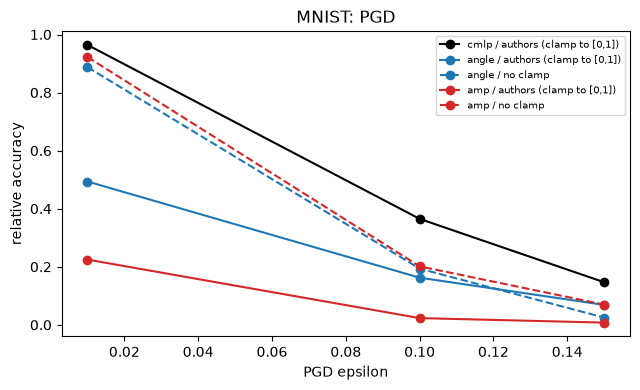

In [15]:
PAPER_T8 = {   # Table 8, 2-layer rows: relative accuracy; key (dataset, attack, eps, model) with model in cmlp / angle / amp
    ("MNIST", "FGSM", 0.01, "cmlp"): 0.98, ("MNIST", "FGSM", 0.01, "angle"): 0.49, ("MNIST", "FGSM", 0.01, "amp"): 0.30,
    ("MNIST", "FGSM", 0.10, "cmlp"): 0.33, ("MNIST", "FGSM", 0.10, "angle"): 0.05, ("MNIST", "FGSM", 0.10, "amp"): 0.10,
    ("MNIST", "FGSM", 0.15, "cmlp"): 0.17, ("MNIST", "FGSM", 0.15, "angle"): 0.01, ("MNIST", "FGSM", 0.15, "amp"): 0.04,
    ("MNIST", "PGD", 0.01, "cmlp"): 0.98, ("MNIST", "PGD", 0.01, "angle"): 0.48, ("MNIST", "PGD", 0.01, "amp"): 0.27,
    ("MNIST", "PGD", 0.10, "cmlp"): 0.09, ("MNIST", "PGD", 0.10, "angle"): 0.04, ("MNIST", "PGD", 0.10, "amp"): 0.03,
    ("MNIST", "PGD", 0.15, "cmlp"): 0.02, ("MNIST", "PGD", 0.15, "angle"): 0.01, ("MNIST", "PGD", 0.15, "amp"): 0.00,
    ("AZ", "FGSM", 0.01, "cmlp"): 0.97, ("AZ", "FGSM", 0.01, "angle"): 0.39, ("AZ", "FGSM", 0.01, "amp"): 0.34,
    ("AZ", "FGSM", 0.10, "cmlp"): 0.30, ("AZ", "FGSM", 0.10, "angle"): 0.32, ("AZ", "FGSM", 0.10, "amp"): 0.02,
    ("AZ", "FGSM", 0.15, "cmlp"): 0.13, ("AZ", "FGSM", 0.15, "angle"): 0.28, ("AZ", "FGSM", 0.15, "amp"): 0.01,
    ("AZ", "PGD", 0.01, "cmlp"): 0.97, ("AZ", "PGD", 0.01, "angle"): 0.39, ("AZ", "PGD", 0.01, "amp"): 0.33,
    ("AZ", "PGD", 0.10, "cmlp"): 0.10, ("AZ", "PGD", 0.10, "angle"): 0.31, ("AZ", "PGD", 0.10, "amp"): 0.01,
    ("AZ", "PGD", 0.15, "cmlp"): 0.02, ("AZ", "PGD", 0.15, "angle"): 0.26, ("AZ", "PGD", 0.15, "amp"): 0.00,
}


def fgsm(model, x, y, eps, lo, hi):
    x = x.clone().requires_grad_(True)
    g, = torch.autograd.grad(F.nll_loss(model(x), y), x)
    xa = x.detach() + eps * g.sign()
    return xa if lo is None else xa.clamp(lo, hi)


def pgd(model, x, y, eps, steps, lo, hi, seed, alpha=None, rand_start=True):
    gen = torch.Generator().manual_seed(seed)
    alpha = alpha or 1.25 * eps / steps
    xa = x + (torch.rand(x.shape, generator=gen) * 2 - 1) * eps if rand_start else x.clone()          # random start
    xa = xa if lo is None else xa.clamp(lo, hi)
    for _ in range(steps):
        xa = xa.detach().requires_grad_(True)
        g, = torch.autograd.grad(F.nll_loss(model(xa), y), xa)
        xa = xa.detach() + alpha * g.sign()
        xa = x + (xa - x).clamp(-eps, eps)                                 # project on the L_inf ball
        xa = xa if lo is None else xa.clamp(lo, hi)
    return xa.detach()


def attacked_accuracy(model, X, y, attack, eps, bounds, bs=100):
    model.eval()
    lo, hi = bounds if bounds else (None, None)
    hit = 0
    for i in range(0, len(X), bs):
        xb, yb = X[i:i + bs], y[i:i + bs]
        if attack == "FGSM":
            xa = fgsm(model, xb, yb, eps, lo, hi)
        elif isinstance(model, CMLP):      # the authors' classical PGD script: 40 steps of 0.01, no random start
            xa = pgd(model, xb, yb, eps, 40, lo, hi, SEED + i, alpha=0.01, rand_start=False)
        else:
            xa = pgd(model, xb, yb, eps, PGD_STEPS, lo, hi, SEED + i)
        with torch.no_grad():
            hit += int((model(xa).argmax(1) == yb).sum())
    return hit / len(X)


EVA = {}      # (dataset, model-short, attack, eps, protocol) -> relative accuracy
short = lambda kind: "cmlp" if kind == "cmlp" else kind.split(":")[0]
for name in ATTACK_DATASETS:
    if name not in DATA:
        continue
    D = DATA[name]
    tr, va, te = SPLITS[(name, 0)]
    te = te[:ATTACK_N]
    for kind in ["cmlp", f"angle:{LAYERS_ANGLE[0]}", f"amp:{LAYERS_AMP[0]}"]:
        res = BASE[(name, kind, 0)]
        model, key = res["model"], res["key"]
        X, y = T(D[key + "_te"][te]), T(D["y_te"][te], torch.long)
        clean = accuracy(model, X, y)
        for protocol, bounds in [("authors (clamp to [0,1])", (0.0, 1.0)), ("no clamp", None if kind != "cmlp" else (0.0, 1.0))]:
            for attack in ("FGSM", "PGD"):
                for eps in EPS_LIST:
                    acc = attacked_accuracy(model, X, y, attack, eps, bounds)
                    EVA[(name, short(kind), attack, eps, protocol)] = (acc / clean if clean > 0 else float("nan"), 100 * clean, 100 * acc)
        print(f"[{name}] {kind:<9} clean accuracy on the {len(te)} attacked test samples: {100 * clean:.1f}%", flush=True)

rows = []
for (name, m, attack, eps, protocol), (rel, c, a) in EVA.items():
    rows.append(dict(dataset=name, model=m, attack=attack, eps=eps, protocol=protocol, rel_acc=round(rel, 2), paper=PAPER_T8.get((name, attack, eps, m)) if protocol.startswith("authors") or m == "cmlp" else None))
EVAdf = pd.DataFrame(rows)
for name in ATTACK_DATASETS:
    if name not in DATA:
        continue
    piv = EVAdf[EVAdf.dataset == name].pivot_table(index=["attack", "eps"], columns=["protocol", "model"], values="rel_acc")
    print(f"\nTable 8 ({name}): relative accuracy under attack (notebook).  Columns = protocol / model")
    print(piv.to_string())
    pp = pd.DataFrame([{"attack": a, "eps": e, **{m: PAPER_T8.get((name, a, e, m)) for m in ("cmlp", "angle", "amp")}} for a in ("FGSM", "PGD") for e in EPS_LIST])
    print(f"Paper Table 8 ({name}, 2 layers):"); print(pp.to_string(index=False))

fig, axes = plt.subplots(1, len(ATTACK_DATASETS), figsize=(6.5 * len(ATTACK_DATASETS), 4), squeeze=False)
for ax, name in zip(axes[0], [n for n in ATTACK_DATASETS if n in DATA]):
    for m, col in [("cmlp", "k"), ("angle", "tab:blue"), ("amp", "tab:red")]:
        for protocol, ls in [("authors (clamp to [0,1])", "-"), ("no clamp", "--")]:
            if m == "cmlp" and ls == "--":
                continue
            ys_ = [EVA[(name, m, "PGD", e, protocol)][0] for e in EPS_LIST]
            ax.plot(EPS_LIST, ys_, ls, marker="o", color=col, label=f"{m} / {protocol}")
    ax.set_xlabel("PGD epsilon"); ax.set_ylabel("relative accuracy"); ax.set_title(f"{name}: PGD"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()


## 11. Paper vs this notebook, claim by claim

Tolerances: accuracy within 2 points, ratios within 0.05, attack-success rates within 5 points ("reproduced"); otherwise "not reached" / "exceeded" with the gap visible in the table; "cannot be checked" when the experiment was not run
(noise, 50 layers, hardware).  In `FAST_MODE` the budgets are far below the paper's (see the configuration cell), so many absolute accuracies are *not reached*; the qualitative rows are the informative ones.

In [16]:
def verdict(nb, paper, tol):
    if nb is None or paper is None or (isinstance(nb, float) and math.isnan(nb)):
        return "cannot be checked"
    if abs(nb - paper) <= tol:
        return "reproduced"
    return "exceeded" if nb > paper else "not reached"


def fmt(v, d=2):
    return "-" if v is None else (f"{v:.{d}f}" if isinstance(v, (int, float, np.floating)) else str(v))


rows = []
add = lambda claim, paper, nb, v, note="": rows.append(dict(claim=claim, paper=paper, notebook=nb, verdict=v, note=note))

# --- Table 2 -------------------------------------------------------------------------------------------------
for name in DATASETS:
    pf = PAPER_T2[(name, "cmlp", 0)][0]
    nb = FULLRES.get((name, "cmlp"))
    add(f"T2 {name}: CMLP accuracy, full data (%)", pf, fmt(nb), verdict(nb, pf, 2.0))
    for enc, Ls in (("angle", LAYERS_ANGLE), ("amp", LAYERS_AMP)):
        for L in Ls:
            ps = PAPER_T2.get((name, enc, L), (None, None))[1]
            nb = mean_std([100 * BASE[(name, f"{enc}:{L}", s)]["acc"] for s in range(N_SEEDS)])[0]
            add(f"T2 {name}: QMLP-{enc} {L} layers, subset accuracy (%)", ps, fmt(nb, 1), verdict(nb, ps, 2.0),
                f"notebook budget: {SUB_PER_CLASS}/class, {EPOCHS_Q} epochs, {N_SEEDS} seed(s)")
        if (name, f"{enc}:{Ls[0]}") in FULLRES:
            pf = PAPER_T2.get((name, enc, Ls[0]), (None, None))[0]
            add(f"T2 {name}: QMLP-{enc} {Ls[0]} layers, full-data accuracy (%)", pf, fmt(FULLRES[(name, f'{enc}:{Ls[0]}')], 1), verdict(FULLRES[(name, f'{enc}:{Ls[0]}')], pf, 2.0))
add("T2: noisy (depolarizing p=0.01) columns, 50-layer models", "see Table 2", "not run", "cannot be checked", "needs a density-matrix/Aer noise simulation; out of CPU budget")
if len(LAYERS_AMP) > 1 or len(LAYERS_ANGLE) > 1:
    pass

# --- Table 3 -------------------------------------------------------------------------------------------------
for (name, kind, ls), pv in PAPER_T3.items():
    if name in ATTACK_DATASETS and (name, kind, ls, 0) in LF:
        nb = mean_std([LF[(name, kind, ls, s)][0] for s in range(N_SEEDS)])[0]
        add(f"T3 {name}: {kind} label flipping 50%, smoothing={ls}", pv, fmt(nb), verdict(nb, pv, 0.05))
for name in ATTACK_DATASETS:
    if name in DATA and (name, "cmlp", "N", 0) in LF:
        cm = mean_std([LF[(name, "cmlp", "N", s)][0] for s in range(N_SEEDS)])[0]
        qm = np.mean([mean_std([LF[(name, k, "N", s)][0] for s in range(N_SEEDS)])[0] for k in KINDS if k != "cmlp"])
        add(f"T3 {name}: claim 'QMLP keeps a higher relative accuracy than CMLP under label flipping'", "QMLP ~0.9 vs CMLP ~0.5",
            f"QMLP mean {qm:.2f} vs CMLP {cm:.2f}", "reproduced" if qm > cm + 0.1 else "not reached")

for name, v in LF_RELEASED.items():
    add(f"T3 {name}: CMLP ratio as computed by the authors' released script (clean model, flipped TEST labels)", PAPER_T3[(name, "cmlp", "N")], fmt(v), verdict(v, PAPER_T3[(name, "cmlp", "N")], 0.05),
        "that script does not poison the training set (see Section 12)")

# --- Tables 4-5 ----------------------------------------------------------------------------------------------
for tag, store, paper, tol, j in (("T4 QUID relative accuracy (w/o Q-Detection)", QUID, PAPER_T4, 0.05, 0), ("T5 QUID ASR % (w/o Q-Detection)", QUID, PAPER_T5, 5.0, 1)):
    hits = tot = 0
    for (name, kind, ratio, s), val in store.items():
        if s:
            continue
        enc, L = kind.split(":")
        pv = paper.get((name, enc, int(L), ratio))
        if pv:
            tot += 1; hits += abs(val[j] - pv[0]) <= tol
    add(f"{tag}: cells within tolerance (+-{tol})", f"{tot} cells", f"{hits} of {tot} within tolerance", "reproduced" if tot and hits >= 0.8 * tot else ("partially" if hits else ("cannot be checked" if not tot else "not reached")))
for name in ATTACK_DATASETS:
    for kind in [k for k in KINDS if k != "cmlp"]:
        asr = [QUID[(name, kind, r, 0)][1] for r in QUID_RATIOS if (name, kind, r, 0) in QUID]
        if len(asr) == len(QUID_RATIOS):
            add(f"T5 {name} {kind}: ASR grows with the poison ratio (qualitative)", "increases 0.1 -> 0.5", " / ".join(f"{a:.0f}" for a in asr), "reproduced" if asr[-1] > asr[0] else "not reached")
qd = [(k, v) for k, v in QUIDQD.items() if k[3] == 0]
if qd:
    better = sum(v[1] < QUID[k][1] for k, v in qd)
    add("T5: Q-Detection lowers the QUID ASR (qualitative)", "lowers ASR, mostly at 0.3", f"lowered in {better} of {len(qd)} settings", "reproduced" if better > len(qd) / 2 else "not reached")

# --- Table 6 -------------------------------------------------------------------------------------------------
for (name, kind, ratio, clamp, s), (rc, asr, ac) in HZ.items():
    if s or not clamp or name != "MNIST":
        continue
    enc, L = kind.split(":")
    pc = PAPER_T6.get((enc, int(L)), {}).get(ratio)
    if pc:
        add(f"T6 MNIST {kind}: HZ backdoor ASR % at poison ratio {ratio}", pc[1], fmt(asr, 1), verdict(asr, pc[1], 5.0), f"relative CDA {rc:.2f} (paper {pc[0]}); clean model on triggered inputs: {ac:.1f}%")

# --- Table 7 -------------------------------------------------------------------------------------------------
for (name, L), (pc, pa) in PAPER_T7.items():
    if (name, L, 0) in TROJ:
        m = np.mean([TROJ[(name, L, s)][1] for s in range(N_SEEDS)])
        chance = 100 / DATA[name]["n_classes"]
        add(f"T7 {name} L={L}: QTrojan ASR % (paper: fails, near chance {chance:.1f}%)", pa, fmt(m, 1), verdict(m, pa, 5.0), f"within +-5 pts of chance: {abs(m - chance) <= 5}")

for name in ATTACK_DATASETS:
    asrs = [np.mean([TROJ[(name, L, s)][1] for s in range(N_SEEDS)]) for L in LAYERS_ANGLE if (name, L, 0) in TROJ]
    if asrs:
        add(f"T7 {name}: QTrojan fails to steer predictions to the target class (qualitative)", "ASR <= 17%, far below 100% of the original", " / ".join(f"{a:.1f}" for a in asrs), "reproduced" if max(asrs) <= 25 else "not reached")

# --- Table 8 -------------------------------------------------------------------------------------------------
for (name, m, attack, eps, protocol), (rel, c, a) in EVA.items():
    if protocol.startswith("authors") or m == "cmlp":
        pv = PAPER_T8.get((name, attack, eps, m))
        if m == "cmlp" and not protocol.startswith("authors"):
            continue
        add(f"T8 {name}: {m} 2 layers, {attack} eps={eps} relative accuracy", pv, fmt(rel), verdict(rel, pv, 0.05))
add("T8: 50-layer QMLP under FGSM/PGD", "Table 8 rows 'layers 50'", "not run", "cannot be checked", "50-layer simulation is out of CPU budget")
add("Sec 5.5/7: QTrojan on hardware / noisy backends, randomized-gate defence", "-", "not run", "cannot be checked", "hardware-level / excessive simulation cost (the authors also skip some)")

CMP = pd.DataFrame(rows)
pd.set_option("display.width", 250, "display.max_colwidth", 90, "display.max_rows", 500)
print(CMP.to_string(index=False))
print("\nverdict counts:", CMP["verdict"].value_counts().to_dict())


                                                                                              claim                                      paper                    notebook           verdict                                                                    note
                                                             T2 MNIST: CMLP accuracy, full data (%)                                      96.63                       95.84        reproduced                                                                        
                                                 T2 MNIST: QMLP-angle 2 layers, subset accuracy (%)                                       41.9                        51.6          exceeded                         notebook budget: 100/class, 8 epochs, 1 seed(s)
                                                   T2 MNIST: QMLP-amp 2 layers, subset accuracy (%)                                       45.5                        40.4       not reached                         note

## 12. Reading the paper critically

* **A survey with an unusually transparent experimental section.** The authors publish code, data and even the 5/10-layer results, and they say plainly where the quantum models are *not* better (QTrojan fails, ratios above 1 under noise are artefacts of near-random baselines).  The central quantitative message,
  "QMLPs are far more vulnerable to FGSM/PGD, but more robust to label flipping", is however confounded as discussed next.
* **Clamping artefact (Section 10).** The evaluation code clamps adversarial inputs to [0, 1]. For MNIST pixels this is right, but the QMLP inputs are PCA coordinates, of which a large share is negative (printed in the exploration section).
  A clamp therefore *moves the data* before any gradient step matters, which explains why even eps = 0.01 costs the quantum models half of their accuracy while the CMLP loses 2 %.  The "no clamp" rows show how much of the gap is due to the clamp.
  The same clipping is used for the HZ backdoor trigger. In the executed FAST run the amplitude-encoded victim reaches ASR 100 % when the triggered inputs are clipped to [0, 1], but only 13.8 % when the very same trigger is added without clipping (Table 6 cell, `clamp_to_01 = False`): the near-perfect ASR is produced by the clipping (a conspicuous distribution shift that is easy to learn), not by the optimised perturbation. Note also that the proxy itself is fooled on 40-50 % of the unclipped triggered inputs, so the unclipped control is the fair reference for the trigger's own strength (single seed, small data: treat as indicative).
* **How the CMLP number in Table 3 seems to arise.** The released classical label-flipping script evaluates a clean model on a test set with 50 % shifted labels (Section 6 reproduces this: relative accuracy about 0.5 by construction), while the QMLP scripts really poison the training set.
  If that script produced Table 3, the headline "CMLP loses 50 %, QMLPs only 10 %" compares an evaluation artefact with a real attack. Our genuine training-time attack on the CMLP is printed next to it. (We only inspected the scripts in the public repository; the authors may have used another one for the paper.)
* **Ceiling effect in label flipping.** A 0.93 relative accuracy of a model that starts at 46-66 % is not the same evidence of robustness as 0.50 for a 96.6 % model; the paper says so itself.  The CMLP uses the full 784 / 2,439 features while the QMLP sees 9 numbers (angle) - the comparison mixes
  "quantum" with "tiny input".  A fair control is a *classical* model on the same 9 PCA features (the RandomForest / SVC rows above).
* **Model selection on the test set.** The released scripts keep the checkpoint with the best test accuracy (and early-stop on test loss); the reported numbers are therefore optimistic. We use a clean validation split.
* **Noise.** The depolarizing columns (p = 0.01 on the transpiled RX, RZ, X, CX gates) drive amplitude-encoded models to ~10 % accuracy; the paper's "noise as a natural defence" reading for QUID is therefore mostly "the model is broken anyway".  We could not check any noisy number.
* **Statistics.** Three seeds and subset sizes of 7,000 are small; many "significant" p-values are across such few runs.
* **QTrojan** is replicated from a 2/4-class, 16-qubit setting; failing on 10/23 classes with 9 qubits is a statement about that adaptation, not about the original attack. With the gates on the circuit output no longer depends on the input (the run prints the share of predictions falling into one class), so QTrojan degrades to a denial-of-service that lands on an arbitrary class; it is a targeted backdoor only if that class happens to be the target.
* **What does reproduce.** Fully dependable here: the architecture and its parameter counts, the existence of the ceiling effect in label flipping, QUID's monotone rise of ASR with the poison ratio, QTrojan's failure to steer predictions, and the large vulnerability of the quantum models to gradient attacks.

## 13. Exercises

1. **Fair classical control.** Train an MLP and a logistic regression on the *same 9 PCA features* and repeat the 50 % label-flipping experiment. Is the quantum model still "more robust"?
2. **The clamp.** In Section 10 replace the clamp bounds by the min/max of each PCA coordinate on the training set. How do the QMLP rows of Table 8 change, and does the CMLP-versus-QMLP ranking at eps = 0.10 survive?
3. **Depth.** Set `LAYERS_ANGLE = [2, 5]` and `LAYERS_AMP = [2, 5]` (and `FAST_MODE = False` budgets for one dataset). Do deeper amplitude circuits really give higher clean accuracy, and what happens to their PGD robustness?
4. **QUID vs random flipping.** Reuse `flip_labels` to poison the same fraction of labels *randomly* and compare with QUID at the same epsilon: does the quantum-geometry choice of labels hurt more than random relabelling?
5. **Noise.** Add a depolarizing channel (p = 0.01) after every gate of the PennyLane QNode with `default.mixed` and evaluate a trained 2-layer angle model on 100 test samples. Compare with the paper's Table 2 noisy columns.